# Notebook 04 — SuperSimpleNet

## Research questions and execution status
Can learned discrimination of spatially masked feature perturbations improve real defect detection, calibration and inference cost? Does the feature adapter help? Can a smaller extractor preserve useful discrimination?

This chronological architecture and pilot record precedes development selection and official test access. Cells explicitly labeled **artifact replay** load genuine earlier measurements; subsequent diagnostic cells execute live. The complete benchmark is **not complete** at this point. Earlier models, records and partitions are preserved.

## Original architecture and sources
Read the [ICPR paper, arXiv v2](https://arxiv.org/html/2408.03143v2) alongside the [official source pinned at 98ab4d5fbdcdef528fafbc42e4b5ee15f08f5a7d](https://github.com/blaz-r/SuperSimpleNet/tree/98ab4d5fbdcdef528fafbc42e4b5ee15f08f5a7d). The source's later JIMS default uses unadapted classifier features; here the original ICPR adapted-classifier path is explicit. MIT attribution is retained under `docs/third_party/`.

Basic CNN learned normal/synthetic RGB discrimination. The autoencoder minimized reconstruction error. PatchCore stored normal local features and searched nearest neighbors. SuperSimpleNet instead learns dense and image-level discrimination after frozen pretrained feature extraction, with synthetic perturbations inserted into adapted features rather than RGB images. Inference needs no memory-bank search and no synthetic generator.

## Mathematical flow
Let $F_2,F_3$ be frozen ImageNet features. First align both to $64\times64$, concatenate, and apply average pooling: $z=P_3[U_2F_2(x);U_4F_3(x)]$. A learned pointwise affine adapter gives $a=W_a*z+b_a$.

Training duplicates $a$ and independently perturbs **both** copies: $\tilde a=a+M\odot\epsilon$, $\epsilon\sim\mathcal N(0,0.015^2 I)$. $M=1[p>0.2]$ for Perlin gradient noise $p$, with approximately half of masks forced empty. Dense target is $M$ and image target is $y=1[\max M>0]$. Clean and altered features share the same normal source distribution. No real defects enter training.

The segmentation branch is $s=W_2*\operatorname{LeakyReLU}(\operatorname{BN}(W_1*\tilde a))$. The detector computes $d=\operatorname{ReLU}(\operatorname{BN}(W_5*[\tilde a;\operatorname{stopgrad}(s)]))$ and a linear scalar from max/mean pooling of both $d$ and $s$. Detaching every segmentation route prevents classifier gradients from corrupting localization, while classification still updates the adapter through its feature input.

With focal $\ell_f(p,t)=-(1-p_t)^4\log p_t$, optimize $L=L_{\rm margin}+L_f(s,M)+L_f(c,y)$. The margin averages normal and anomaly pixels **separately**, using $\max(0,s+0.5)$ and $\max(0,0.5-s)$. Empty-class means contribute zero. AdamW uses adapter LR $10^{-4}$, head LR $2\cdot10^{-4}$, group-specific decay, and fixed scheduler fractions .8/.9. Final pixel map is bilinear-upsampled raw segmentation logits followed by Gaussian smoothing $\sigma=4$. The detector produces a separate raw image logit; max/top1% map rules are development candidates, not interchangeable probabilities.

Complexity is fixed per image: frozen CNN plus pointwise adapter/segmentation and a 5x5 classifier convolution. Unlike PatchCore, inference does not scale with normal memory size. Dense 64-grid heads and feature-cache IO can still be expensive.

## Fidelity and intentional differences
Reference widths are 1536/1024/128 with WideResNet50-2 **ImageNet V1**. Lite uses ResNet18 V1 and 384/256/32. We preserve established whole-image 256 geometry and normal-only partitions, use reduced epoch/batch/seed budgets, and add gradient clipping at10. Our independently seeded Perlin implementation is not RNG-identical to the official one. Raw logits avoid official test-derived min/max normalization. These reduced-budget models are not claimed to reproduce paper results. See the complete preregistered [protocol](../reports/supersimplenet/protocol.md).


In [1]:
from pathlib import Path
import sys,json,time,inspect
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
import numpy as np,pandas as pd,matplotlib.pyplot as plt,torch,psutil
from anomaly_detection.supersimplenet import *
from anomaly_detection.ssn_research import experiment,feature_cache,model_for,predict
from anomaly_detection.cnn_research import read_partition,require_fitting,load_resized
from anomaly_detection.data import CATEGORIES,sha256
torch.set_num_threads(4)
assert torch.cuda.is_available()
torch.backends.cuda.matmul.allow_tf32=False
print(torch.__version__,torch.cuda.get_device_name(0))
print('VRAM GiB:',torch.cuda.get_device_properties(0).total_memory/2**30)
print('RAM GiB:',psutil.virtual_memory().total/2**30)


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\shaik\\.matplotlib\\fontlist-v390.json.matplotlib-lock'


2.11.0+cu128 NVIDIA GeForce RTX 4060 Laptop GPU
VRAM GiB: 7.99560546875
RAM GiB: 31.70067596435547


## Architecture illustration
Only the training path injects noise. Calibration and inference follow the clean adapted-feature path. All masks below are synthetic feature-space targets.

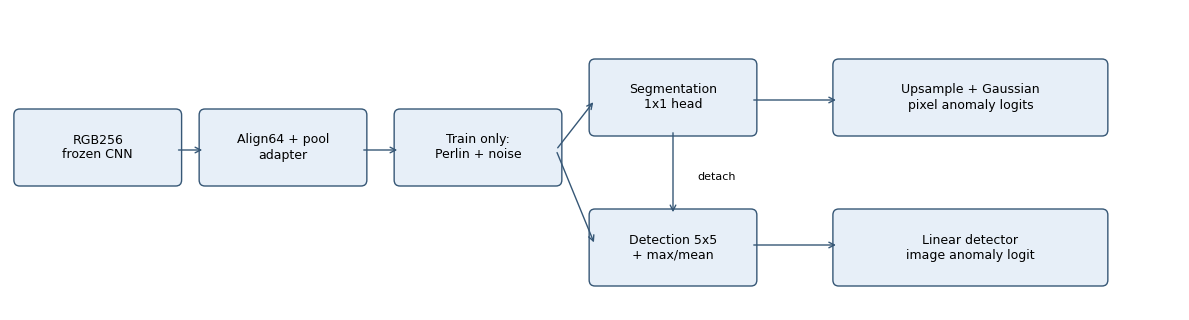

In [2]:
from matplotlib.patches import FancyBboxPatch
fig,ax=plt.subplots(figsize=(12,3.3));ax.set(xlim=(0,12),ylim=(0,3));ax.axis('off')
boxes=[(.1,1.3,1.6,'RGB256\nfrozen CNN'),(2,1.3,1.6,'Align64 + pool\nadapter'),(4,1.3,1.6,'Train only:\nPerlin + noise'),(6,1.8,1.6,'Segmentation\n1x1 head'),(6,.3,1.6,'Detection 5x5\n+ max/mean'),(8.5,1.8,2.7,'Upsample + Gaussian\npixel anomaly logits'),(8.5,.3,2.7,'Linear detector\nimage anomaly logit')]
for x,y,w,t in boxes:
    ax.add_patch(FancyBboxPatch((x,y),w,.65,boxstyle='round,pad=.06',fc='#e7eff8',ec='#365776'));ax.text(x+w/2,y+.325,t,ha='center',va='center',fontsize=9)
for a,b in [((1.7,1.6),(2,1.6)),((3.6,1.6),(4,1.6)),((5.6,1.6),(6,2.1)),((5.6,1.6),(6,.65)),((7.6,2.1),(8.5,2.1)),((7.6,.65),(8.5,.65)),((6.8,1.8),(6.8,.95))]:
    ax.annotate('',xy=b,xytext=a,arrowprops=dict(arrowstyle='->',color='#365776'))
ax.text(7.05,1.3,'detach',fontsize=8);fig.tight_layout()
fig.savefig(ROOT/'reports/supersimplenet/architecture.svg');plt.show()


## Dataset isolation and preprocessing
The shared loader verifies seed-2026 manifests. Fitting and development contain normals only. Pilot fitting/probe sources are disjoint; development normals are never perturbed in their clean diagnostic distribution. Reserved calibration and official test data are not opened in this notebook stage. PIL whole-image RGB bilinear resizing to256 is followed by the correct ImageNet V1 normalization.


In [3]:
fit=read_partition('fit','bottle');dev=read_partition('development','bottle')
require_fitting(fit)
assert not set(fit.path)&set(dev.path)
print('Categories:',CATEGORIES)
print('Bottle fitting/development:',len(fit),len(dev))
print('Pilot fitting/probe/development counts:',32,8,16)


Categories: ('bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper')
Bottle fitting/development: 147 31
Pilot fitting/probe/development counts: 32 8 16


## Implementation: frozen feature extraction and alignment
The actual reusable implementation is exposed below. Upsampling occurs before pooling; existing PatchCore caches have incompatible geometry and are not reused. Deterministic per-image caches are reused across trials/seeds.

In [4]:
print(inspect.getsource(SSNExtractor))
print(inspect.getsource(aggregate_features))


class SSNExtractor(nn.Module):
    """Frozen ImageNet V1 layers 2/3, upscale FIRST to 64, then pool 3x3.

    PatchCore's pooled 32-grid cache is NOT compatible with this computation.
    Uses official V1 normalization with whole-image 256 geometry (paper setting).
    """
    def __init__(self,backbone='resnet18',pretrained=True):
        super().__init__()
        if backbone not in ['resnet18','wide_resnet50_2']:raise ValueError('Unsupported backbone')
        self.backbone=backbone
        weights=ResNet18_Weights.IMAGENET1K_V1 if backbone=='resnet18' else Wide_ResNet50_2_Weights.IMAGENET1K_V1
        self.weight_url=weights.url
        self.channels=384 if backbone=='resnet18' else 1536
        network=(resnet18 if backbone=='resnet18' else wide_resnet50_2)(weights=None)
        if pretrained:
            name=Path(weights.url).name
            local=Path(__file__).resolve().parents[2]/'checkpoints/pretrained'/name
            path=local if local.exists() else Path(torch.hub.get_d

## Feature anomaly implementation and exact targets
Perlin noise uses smooth gradient-lattice interpolation. A binary spatial mask gates independently sampled channel noise; its actual nonempty support determines the image label. The clean cached feature tensor is not modified.

In [5]:
print(inspect.getsource(perlin_noise))
print(inspect.getsource(feature_anomalies))


def perlin_noise(height,width,res_y,res_x,generator):
    """Quintic-interpolated random gradient lattice, not resized white noise."""
    y=torch.arange(height,dtype=torch.float32)*res_y/height
    x=torch.arange(width,dtype=torch.float32)*res_x/width
    yy,xx=torch.meshgrid(y,x,indexing='ij')
    iy=yy.long();ix=xx.long();dy=yy-iy;dx=xx-ix
    angles=2*math.pi*torch.rand(res_y+1,res_x+1,generator=generator)
    gy,gx=angles.sin(),angles.cos()
    def dot(oy,ox):return gy[iy+oy,ix+ox]*(dy-oy)+gx[iy+oy,ix+ox]*(dx-ox)
    fade=lambda t:6*t**5-15*t**4+10*t**3
    upper=torch.lerp(dot(0,0),dot(0,1),fade(dx))
    lower=torch.lerp(dot(1,0),dot(1,1),fade(dx))
    return math.sqrt(2)*torch.lerp(upper,lower,fade(dy))

def feature_anomalies(adapted,mask_generator,noise_generator,noise_std=.015,threshold=.2,normal_probability=.5):
    """Duplicate features; independent Perlin/no-anomaly decisions for BOTH copies.

    All source features are fitting normals, so real-anomaly masks are empty.
   

## Adapter, segmentation and detection heads; losses and training step
The source shows exactly where classification gradients stop. Synthetic generation is explicit and cannot occur in ordinary forward/inference. Margin and focal losses are implemented directly.

In [6]:
print(inspect.getsource(SuperSimpleHeads))
print(inspect.getsource(focal_loss));print(inspect.getsource(training_loss))
print(inspect.getsource(optimizer_for));print(inspect.getsource(anomaly_maps))
from anomaly_detection.ssn_research import train_epoch
print(inspect.getsource(train_epoch))


class SuperSimpleHeads(nn.Module):
    """Reference: C=1536, seg=1024, detection=128; Lite: C=384,256,32.

    The original ICPR formulation uses adapted features for BOTH heads. Every
    classification route through the segmentation map is detached by default;
    classification can still update the adapter through its feature input.
    """
    def __init__(self,channels=384,seg_width=256,det_width=32,adapter_trainable=True,stop_grad=True):
        super().__init__()
        self.adapter=nn.Conv2d(channels,channels,1)
        self.seg=nn.Sequential(nn.Conv2d(channels,seg_width,1),nn.BatchNorm2d(seg_width),
            nn.LeakyReLU(.2),nn.Conv2d(seg_width,1,1,bias=False))
        self.det=nn.Sequential(nn.Conv2d(channels+1,det_width,5,padding=2),nn.BatchNorm2d(det_width),nn.ReLU())
        self.fc=nn.Linear(2*det_width+2,1)
        self.stop_grad=stop_grad
        for module in self.modules():
            if isinstance(module,(nn.Conv2d,nn.Linear)):nn.init.xavier_normal_(module.weigh

## Initial verification and chronological pilot: artifact replay
Five CPU tests passed for feature shapes/freezing, exact perturbation support, losses/gradients, detached classifier routing, checkpoint replay, score orientation and aggregation. The following results were measured by `scripts/pilot_supersimplenet.py`; this cell replays those artifacts and does not claim to retrain them live.

**Hypothesis R:** the reference-width architecture fits safely and is affordable for45 fits. **Hypothesis L:** 20 Lite epochs can learn the reference perturbation on32 fitting normals. Neither hypothesis uses official defect data.

{'layer_shapes': [[4, 512, 32, 32], [4, 1024, 16, 16]], 'aggregated_shape': [4, 1536, 64, 64], 'segmentation_shape': [8, 1, 64, 64], 'detection_shape': [8], 'head_parameters': 8856835, 'mean_step_seconds': 0.15902596000014455, 'projected_40_epoch_45_fit_training_seconds': 12270.443073611154, 'training_resources': {'seconds': 2.579084100005275, 'cpu_initial_rss_bytes': 1615908864, 'cpu_peak_rss_bytes': 2188419072, 'cpu_peak_increment_bytes': 572510208, 'cpu_sampling_seconds': 0.05, 'peak_gpu_allocated_bytes': 1674352640, 'peak_gpu_reserved_bytes': 2629828608}}
Lite parameters: 555331 resources: {'seconds': 16.389204599996447, 'cpu_initial_rss_bytes': 2256863232, 'cpu_peak_rss_bytes': 2349768704, 'cpu_peak_increment_bytes': 92905472, 'cpu_sampling_seconds': 0.05, 'peak_gpu_allocated_bytes': 761477632, 'peak_gpu_reserved_bytes': 1281359872}
Checkpoint replay exact: True


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,normal_development_q95,objective
head,0.390625,0.448657,0.0,0.0,0.0,0.0,"[[8, 0], [8, 0]]",0.17782,0.05638,0.284223
max,0.59375,0.660218,0.125,0.125,0.5,0.2,"[[7, 1], [7, 1]]",0.17782,0.613795,0.367035
top1pct,0.59375,0.643029,0.0,0.0,0.0,0.0,"[[8, 0], [8, 0]]",0.17782,0.540258,0.385785


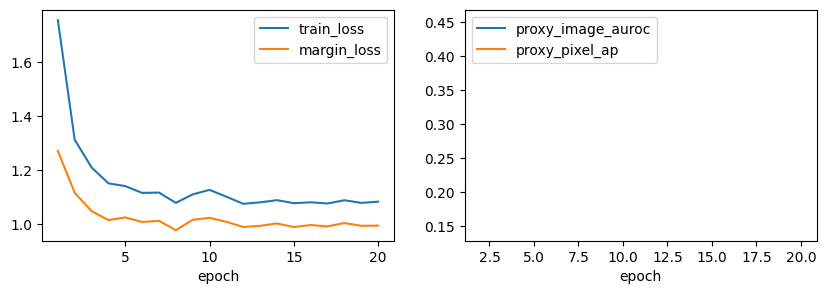

In [7]:
reference=json.loads((ROOT/'reports/supersimplenet/reference_feasibility.json').read_text())
pilot=json.loads((ROOT/'reports/supersimplenet/runs/04-pilot-lite-bottle-s2026-v1-result.json').read_text())
print({k:reference[k] for k in ['layer_shapes','aggregated_shape','segmentation_shape','detection_shape','head_parameters','mean_step_seconds','projected_40_epoch_45_fit_training_seconds','training_resources']})
print('Lite parameters:',pilot['parameters'],'resources:',pilot['resources'])
print('Checkpoint replay exact:',pilot['checkpoint_replay_exact'])
display(pd.DataFrame(pilot['development']['candidates']).T)
h=pd.DataFrame(pilot['history']);fig,axes=plt.subplots(1,2,figsize=(10,3))
h.plot(x='epoch',y=['train_loss','margin_loss'],ax=axes[0]);h.plot(x='epoch',y=['proxy_image_auroc','proxy_pixel_ap'],ax=axes[1]);plt.show()


**Measured interpretation and decision:** the reference path fits memory but projects beyond the prespecified 90-minute training budget, so it is rejected for broad study. Lite losses decrease but the margin stays near1, image discrimination is below chance and localization AP remains weak on this tiny proxy. This does not establish useful learning. Do not launch the all-category benchmark.

## Bounded diagnosis: stronger planned perturbation — live training
**Hypothesis N:** the planned .05 standard deviation provides a more learnable signal than .015 in the reduced-width, short-budget pilot. All other settings, seed, 32 normal fitting sources, eight disjoint probe sources and 16 clean development normals are unchanged. This is one predeclared magnitude candidate, not a search over real defects. The following code performs training live and preserves every epoch and checkpoint.

In [8]:
config=dict(backbone='resnet18',channels=384,seg_width=256,det_width=32,adapter_trainable=True,
    noise_std=.05,loss='margin_focal',seed=2026,batch_size=8,extraction_batch=8,epochs=20,
    validation_every=2,hypothesis='Larger planned feature perturbations improve learnability under the same bounded Lite pilot')
extractor=SSNExtractor('resnet18').cuda()
diagnostic=experiment('04-pilot-lite-noise05-bottle-s2026-v1','bottle',config,extractor,phase='pilot',pilot=True)
display(pd.DataFrame(diagnostic['development']['candidates']).T)
print('Checkpoint exact:',diagnostic['checkpoint_replay_exact'],'resources:',diagnostic['resources'])


{"experiment": "04-pilot-lite-noise05-bottle-s2026-v1", "train_loss": 1.7844929099082947, "gradient_norm": 17.29622519016266, "synthetic_fraction": 0.5, "target_pixel_fraction": 0.12175369262695312, "segmentation_focal": 0.19640105217695236, "margin_loss": 1.2721602320671082, "detection_focal": 0.3159316536039114, "train_epoch_seconds": 1.4159711000029347, "epoch": 1, "elapsed_seconds": 3.2109314000044833}


{"experiment": "04-pilot-lite-noise05-bottle-s2026-v1", "train_loss": 1.3358725607395172, "gradient_norm": 7.202768921852112, "synthetic_fraction": 0.484375, "target_pixel_fraction": 0.12669754028320312, "segmentation_focal": 0.128070667386055, "margin_loss": 1.1239597499370575, "detection_focal": 0.08384212758392096, "train_epoch_seconds": 0.6243567000055918, "proxy_objective": 0.13315649316656092, "proxy_image_auroc": 0.21875, "proxy_pixel_ap": 0.1475629863331218, "proxy_loss": 1.1921768188476562, "normal_map_focal": 0.045053429901599884, "normal_head_focal": 0.003603713121265173, "epoch": 2, "elapsed_seconds": 4.507210300005681}


{"experiment": "04-pilot-lite-noise05-bottle-s2026-v1", "train_loss": 1.217642217874527, "gradient_norm": 6.130073189735413, "synthetic_fraction": 0.578125, "target_pixel_fraction": 0.14192581176757812, "segmentation_focal": 0.09209035336971283, "margin_loss": 1.0510376989841461, "detection_focal": 0.07451416738331318, "train_epoch_seconds": 0.5579832999937935, "epoch": 3, "elapsed_seconds": 5.0698300000003655}


{"experiment": "04-pilot-lite-noise05-bottle-s2026-v1", "train_loss": 1.1314653754234314, "gradient_norm": 3.6242160201072693, "synthetic_fraction": 0.53125, "target_pixel_fraction": 0.13655471801757812, "segmentation_focal": 0.07207253202795982, "margin_loss": 1.0037522912025452, "detection_focal": 0.055640559643507004, "train_epoch_seconds": 0.5726058000000194, "proxy_objective": 0.1976935802768054, "proxy_image_auroc": 0.328125, "proxy_pixel_ap": 0.16726216055361073, "proxy_loss": 1.32879638671875, "normal_map_focal": 0.03737542778253555, "normal_head_focal": 0.0005760792410001159, "epoch": 4, "elapsed_seconds": 6.219728700001724}


{"experiment": "04-pilot-lite-noise05-bottle-s2026-v1", "train_loss": 1.1084512770175934, "gradient_norm": 3.3367320895195007, "synthetic_fraction": 0.390625, "target_pixel_fraction": 0.0971221923828125, "segmentation_focal": 0.0603802427649498, "margin_loss": 0.999319538474083, "detection_focal": 0.04875150602310896, "train_epoch_seconds": 0.5903220000036526, "epoch": 5, "elapsed_seconds": 6.816985900004511}


{"experiment": "04-pilot-lite-noise05-bottle-s2026-v1", "train_loss": 1.0667344331741333, "gradient_norm": 2.3679280877113342, "synthetic_fraction": 0.4375, "target_pixel_fraction": 0.1143798828125, "segmentation_focal": 0.04932264145463705, "margin_loss": 0.9720984846353531, "detection_focal": 0.045313342474401, "train_epoch_seconds": 0.6172732999984873, "proxy_objective": 0.26571757169203947, "proxy_image_auroc": 0.359375, "proxy_pixel_ap": 0.172060143384079, "proxy_loss": 1.2699373960494995, "normal_map_focal": 0.0219881534576416, "normal_head_focal": 0.0007623948622494936, "epoch": 6, "elapsed_seconds": 8.001712400000542}


... (12 outputs left out)

{"experiment": "04-pilot-lite-noise05-bottle-s2026-v1", "train_loss": 0.9350047260522842, "gradient_norm": 2.111547291278839, "synthetic_fraction": 0.375, "target_pixel_fraction": 0.09683990478515625, "segmentation_focal": 0.03462004102766514, "margin_loss": 0.8685614466667175, "detection_focal": 0.031823225785046816, "train_epoch_seconds": 0.5013478000037139, "epoch": 19, "elapsed_seconds": 18.7183623000019}


{"experiment": "04-pilot-lite-noise05-bottle-s2026-v1", "train_loss": 0.93631611764431, "gradient_norm": 2.7716596126556396, "synthetic_fraction": 0.484375, "target_pixel_fraction": 0.13257598876953125, "segmentation_focal": 0.035075065679848194, "margin_loss": 0.8647525161504745, "detection_focal": 0.03648852836340666, "train_epoch_seconds": 0.5458471999954781, "proxy_objective": 0.5382721065546681, "proxy_image_auroc": 0.8125, "proxy_pixel_ap": 0.264044213109336, "proxy_loss": 0.9493485689163208, "normal_map_focal": 0.02759729139506817, "normal_head_focal": 0.009813559241592884, "epoch": 20, "elapsed_seconds": 19.7359401000067}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,normal_development_q95,objective
head,0.8125,0.821925,0.125,0.0,1.0,0.222222,"[[8, 0], [7, 1]]",0.264044,-0.204896,0.538272
max,0.734375,0.758631,0.5,0.25,0.666667,0.571429,"[[6, 2], [4, 4]]",0.264044,0.565563,0.44921
top1pct,0.78125,0.768651,0.25,0.125,0.666667,0.363636,"[[7, 1], [6, 2]]",0.264044,0.463735,0.503897


Checkpoint exact: True resources: {'seconds': 17.955437799995707, 'cpu_initial_rss_bytes': 949690368, 'cpu_peak_rss_bytes': 2014621696, 'cpu_peak_increment_bytes': 1064931328, 'cpu_sampling_seconds': 0.05, 'peak_gpu_allocated_bytes': 761477632, 'peak_gpu_reserved_bytes': 970981376}


## Synthetic feature diagnostics — live inference
Plot a clean feature channel, planted mask, perturbation magnitude and predicted dense map. These are feature-space diagnostics, not real industrial anomaly evidence. The fixed seeded generator supplies exactly the same proxy support as development scoring.

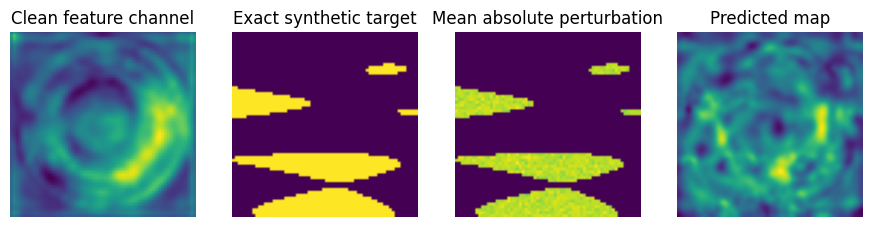

,trial,image_auroc,pixel_ap,last_margin,seconds
0,04-pilot-lite-bottle-s2026-v1,0.390625,0.177820,0.994697,19.944605
1,04-pilot-lite-noise05-bottle-s2026-v1,0.812500,0.264044,0.864753,19.877754


In [9]:
sources=feature_cache(extractor,fit.iloc[32:40],8)
head=model_for(config).cuda().eval()
head.load_state_dict(torch.load(ROOT/diagnostic['checkpoint'],weights_only=True,map_location='cpu')['state_dict'])
with torch.no_grad():
    z=sources.batch(range(8));a=head.adapter(z)
    perturbed,mask,label=feature_anomalies(a,torch.Generator().manual_seed(9901),torch.Generator(device='cuda').manual_seed(9902),noise_std=.05)
    seg,score=head.discriminate(perturbed)
    index=int(torch.where(label>0)[0][0]);delta=(perturbed-torch.cat([a,a])).abs().mean(1)
    maps=anomaly_maps(seg)
    assert torch.isfinite(maps).all() and torch.isfinite(score).all()
    assert torch.equal(delta.ne(0),mask[:,0].bool())
fig,axes=plt.subplots(1,4,figsize=(11,3))
for ax,value,title in zip(axes,[a[index%8,0],mask[index,0],delta[index],maps[index]],['Clean feature channel','Exact synthetic target','Mean absolute perturbation','Predicted map']):
    ax.imshow(value.cpu(),cmap='viridis');ax.set_title(title);ax.axis('off')
plt.show()
display(pd.DataFrame([dict(trial=r['experiment_id'],image_auroc=r['development']['candidates']['head']['auroc'],pixel_ap=r['development']['candidates']['head']['pixel_ap'],last_margin=r['history'][-1]['margin_loss'],seconds=r['wall_seconds']) for r in [pilot,diagnostic]]))


## Gate and next research stages
The measured pilot report and diagnostic decision are stored alongside the notebook. No official test metrics, threshold calibration, frozen final configuration or all-category completeness is claimed here. The next step depends on demonstrated learning on normal-derived synthetic proxies, not a lower loss alone.

The preregistered bounded development study covers bottle/cable/carpet/tile, adaptation, noise and loss behavior, with head/max/top1% aggregation. Calibration will remain separate: higher q95 image and q99.5 pixel normal quantiles, strict `>` decisions, sample counts and uncertainty. Final fitting must precede official test evaluation; no retraining after inspection.

## Comparison and limitations at this stage
No comparison to completed Basic CNN, Autoencoder or PatchCore quality is justified from a tiny synthetic pilot. Prior exact stored results remain unchanged. The future comparison must include matched category scores, precision/recall/FPR/localization, paired uncertainty and measured inference cost, with special attention to leather/carpet false positives and screw detection. Synthetic discrimination may not transfer to real defects; a 64-grid feature representation can lose fine details; tiny held-out sets produce unstable diagnostics; reduced training and widths differ from the publication.

Raw images, weights, dense caches and checkpoints remain local and ignored. This public notebook contains genuine compact outputs. Its training cell executed live; the earlier reference/Lite record was explicitly replayed. The experiment registry is append-only under [experiments](../experiments/), with configurations, hashes and decisions. Full local executed notebook: `outputs/supersimplenet/04_supersimplenet.pilot.executed.ipynb`.


# Continued record: bounded development and frozen confirmation
The preceding pilot contains genuine live training. This continuation **executes artifact analysis** of separately recorded training/evaluation jobs. It does not claim those jobs trained live in this kernel. Execution counts restart for this separate analysis session and are preserved as produced by the kernels. Earlier pending statements describe the chronological pilot state; completed phases below supersede them.

## Implementation exposed as code
The following definitions expose the feature alignment, adapter, synthetic generation, heads, losses, inference, cache and actual fitting loop used by the recorded jobs. The original modules and exact source hashes remain the authoritative job implementation. In this notebook demonstration only, extractor file-root lookup is expressed as the already verified `ROOT` variable. No training job is rerun here.


In [1]:
from pathlib import Path
import sys,json,math
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
import numpy as np,pandas as pd,matplotlib.pyplot as plt,torch
from PIL import Image
from IPython.display import display,Markdown
from anomaly_detection.data import CATEGORIES,autodiscover_data_root,sha256
torch.set_num_threads(4)
report=ROOT/'reports/supersimplenet'
frozen=json.loads((ROOT/'configs/supersimplenet_frozen.json').read_text())
summary={'frozen_configuration_sha256':sha256(ROOT/'configs/supersimplenet_frozen.json')}
display(pd.DataFrame([dict(category=c,**{p:len(__import__('anomaly_detection.cnn_research',fromlist=['read_partition']).read_partition(p,c)) for p in ['fit','development','calibration','test']}) for c in CATEGORIES]))
print('Frozen weights:',frozen['weight_sha256'])


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\shaik\\.matplotlib\\fontlist-v390.json.matplotlib-lock'


,category,fit,development,calibration,test
0,bottle,147,31,31,83
1,cable,158,33,33,150
2,capsule,155,32,32,132
3,carpet,196,42,42,117
4,grid,186,39,39,78
5,hazelnut,275,58,58,110
6,leather,173,36,36,124
7,metal_nut,154,33,33,115
8,pill,187,40,40,167
9,screw,224,48,48,160


Frozen weights: f37072fd47e89c5e827621c5baffa7500819f7896bbacec160b1a16c560e07ec


In [2]:
"""ICPR-style SuperSimpleNet components with explicit resource variants.

Architecture/loss design follows blaz-r/SuperSimpleNet (MIT, copyright 2024
Blaž Rolih); see docs/third_party/SuperSimpleNet_LICENSE.txt. Perlin gradient
noise is implemented independently with explicit seeded generators.
"""
import hashlib,math
from pathlib import Path
import torch
from torch import nn
from torch.nn import functional as F
from torchvision.models import resnet18,wide_resnet50_2,ResNet18_Weights,Wide_ResNet50_2_Weights
from torchvision.transforms.functional import gaussian_blur


class SSNExtractor(nn.Module):
    """Frozen ImageNet V1 layers 2/3, upscale FIRST to 64, then pool 3x3.

    PatchCore's pooled 32-grid cache is NOT compatible with this computation.
    Uses official V1 normalization with whole-image 256 geometry (paper setting).
    """
    def __init__(self,backbone='resnet18',pretrained=True):
        super().__init__()
        if backbone not in ['resnet18','wide_resnet50_2']:raise ValueError('Unsupported backbone')
        self.backbone=backbone
        weights=ResNet18_Weights.IMAGENET1K_V1 if backbone=='resnet18' else Wide_ResNet50_2_Weights.IMAGENET1K_V1
        self.weight_url=weights.url
        self.channels=384 if backbone=='resnet18' else 1536
        network=(resnet18 if backbone=='resnet18' else wide_resnet50_2)(weights=None)
        if pretrained:
            name=Path(weights.url).name
            local=ROOT/'checkpoints/pretrained'/name
            path=local if local.exists() else Path(torch.hub.get_dir())/'checkpoints'/name
            if not path.is_file():raise FileNotFoundError('Acquire and register official weights: '+weights.url)
            self.weight_sha256=hashlib.sha256(path.read_bytes()).hexdigest()
            if not self.weight_sha256.startswith(path.stem.split('-')[-1]):raise ValueError('Weight identity mismatch')
            network.load_state_dict(torch.load(path,map_location='cpu',weights_only=True))
        else:self.weight_sha256='untrained-test-only'
        self.stem=nn.Sequential(network.conv1,network.bn1,network.relu,network.maxpool)
        self.layer1=network.layer1;self.layer2=network.layer2;self.layer3=network.layer3
        self.transform=weights.transforms(resize_size=256,crop_size=256,antialias=True)
        self.requires_grad_(False);self.eval()

    def train(self,mode=True):return super().train(False)

    @torch.no_grad()
    def feature_maps(self,images):
        if images.ndim!=4 or images.shape[1:]!=(3,256,256):raise ValueError('Expected B,3,256,256 RGB')
        first=self.layer1(self.stem(self.transform(images)))
        second=self.layer2(first);third=self.layer3(second)
        return second,third

    def forward(self,images):
        second,third=self.feature_maps(images)
        return aggregate_features(second,third)


def aggregate_features(second,third):
    size=(second.shape[-2]*2,second.shape[-1]*2)
    aligned=[F.interpolate(x,size=size,mode='bilinear',align_corners=True) for x in [second,third]]
    return F.avg_pool2d(torch.cat(aligned,dim=1),3,1,1)


def perlin_noise(height,width,res_y,res_x,generator):
    """Quintic-interpolated random gradient lattice, not resized white noise."""
    y=torch.arange(height,dtype=torch.float32)*res_y/height
    x=torch.arange(width,dtype=torch.float32)*res_x/width
    yy,xx=torch.meshgrid(y,x,indexing='ij')
    iy=yy.long();ix=xx.long();dy=yy-iy;dx=xx-ix
    angles=2*math.pi*torch.rand(res_y+1,res_x+1,generator=generator)
    gy,gx=angles.sin(),angles.cos()
    def dot(oy,ox):return gy[iy+oy,ix+ox]*(dy-oy)+gx[iy+oy,ix+ox]*(dx-ox)
    fade=lambda t:6*t**5-15*t**4+10*t**3
    upper=torch.lerp(dot(0,0),dot(0,1),fade(dx))
    lower=torch.lerp(dot(1,0),dot(1,1),fade(dx))
    return math.sqrt(2)*torch.lerp(upper,lower,fade(dy))


def feature_anomalies(adapted,mask_generator,noise_generator,noise_std=.015,threshold=.2,normal_probability=.5):
    """Duplicate features; independent Perlin/no-anomaly decisions for BOTH copies.

    All source features are fitting normals, so real-anomaly masks are empty.
    Labels are derived from the actual binary perturbation support, never guessed.
    The input is not modified, allowing immutable clean calibration caches.
    """
    if adapted.ndim!=4 or noise_std<=0 or not 0<=normal_probability<=1:raise ValueError('Invalid synthetic configuration')
    duplicated=torch.cat([adapted,adapted],dim=0)
    b,_,h,w=duplicated.shape;masks=[]
    max_y=min(6,int(math.log2(h))+1);max_x=min(6,int(math.log2(w))+1)
    for _ in range(b):
        ry=2**int(torch.randint(0,max_y,(1,),generator=mask_generator))
        rx=2**int(torch.randint(0,max_x,(1,),generator=mask_generator))
        support=(perlin_noise(h,w,ry,rx,mask_generator)>threshold).float()
        if float(torch.rand((),generator=mask_generator))<normal_probability:support.zero_()
        masks.append(support)
    mask=torch.stack(masks)[:,None].to(adapted.device)
    noise=torch.randn(duplicated.shape,device=adapted.device,generator=noise_generator)*noise_std
    perturbed=duplicated+noise*mask
    labels=mask.flatten(1).any(1).float()
    return perturbed,mask,labels


class SuperSimpleHeads(nn.Module):
    """Reference: C=1536, seg=1024, detection=128; Lite: C=384,256,32.

    The original ICPR formulation uses adapted features for BOTH heads. Every
    classification route through the segmentation map is detached by default;
    classification can still update the adapter through its feature input.
    """
    def __init__(self,channels=384,seg_width=256,det_width=32,adapter_trainable=True,stop_grad=True):
        super().__init__()
        self.adapter=nn.Conv2d(channels,channels,1)
        self.seg=nn.Sequential(nn.Conv2d(channels,seg_width,1),nn.BatchNorm2d(seg_width),
            nn.LeakyReLU(.2),nn.Conv2d(seg_width,1,1,bias=False))
        self.det=nn.Sequential(nn.Conv2d(channels+1,det_width,5,padding=2),nn.BatchNorm2d(det_width),nn.ReLU())
        self.fc=nn.Linear(2*det_width+2,1)
        self.stop_grad=stop_grad
        for module in self.modules():
            if isinstance(module,(nn.Conv2d,nn.Linear)):nn.init.xavier_normal_(module.weight)
            if isinstance(module,nn.BatchNorm2d):nn.init.ones_(module.weight)
        self.adapter.requires_grad_(adapter_trainable)

    def discriminate(self,adapted):
        segmentation=self.seg(adapted)
        copied=segmentation.detach() if self.stop_grad else segmentation
        detection=self.det(torch.cat([adapted,copied],dim=1))
        pooled=torch.cat([detection.amax((2,3)),detection.mean((2,3)),
                          copied.amax((2,3)),copied.mean((2,3))],dim=1)
        return segmentation,self.fc(pooled)[:,0]

    def forward(self,features):return self.discriminate(self.adapter(features))

    def synthetic_forward(self,features,mask_generator,noise_generator,**kwargs):
        adapted=self.adapter(features)
        perturbed,mask,labels=feature_anomalies(adapted,mask_generator,noise_generator,**kwargs)
        segmentation,scores=self.discriminate(perturbed)
        return segmentation,scores,mask,labels


def focal_loss(logits,targets,gamma=4):
    ce=F.binary_cross_entropy_with_logits(logits.float(),targets.float(),reduction='none')
    p=logits.float().sigmoid();pt=p*targets+(1-p)*(1-targets)
    return (ce*(1-pt)**gamma).mean()


def training_loss(segmentation,scores,mask,labels,margin=.5,segmentation_loss='margin_focal'):
    if segmentation.shape!=mask.shape or scores.shape!=labels.shape:raise ValueError('Target/output shape mismatch')
    normal=segmentation[mask==0];anomaly=segmentation[mask>0]
    zero=segmentation.sum()*0
    hinge=(F.relu(normal+margin).mean() if len(normal) else zero)+(F.relu(margin-anomaly).mean() if len(anomaly) else zero)
    seg_focal=focal_loss(segmentation,mask)
    if segmentation_loss not in ['margin_focal','focal']:raise ValueError('Unknown loss')
    seg=seg_focal+(hinge if segmentation_loss=='margin_focal' else zero)
    detection=focal_loss(scores,labels)
    return seg+detection,dict(segmentation_focal=float(seg_focal.detach()),margin_loss=float(hinge.detach()),detection_focal=float(detection.detach()))


def anomaly_maps(segmentation,size=(256,256)):
    maps=F.interpolate(segmentation,size=size,mode='bilinear',align_corners=False)
    return gaussian_blur(maps,[25,25],[4.,4.])[:,0]


def image_scores(maps,detection,aggregation='head'):
    if aggregation=='head':return detection
    if aggregation=='max':return maps.flatten(1).amax(1)
    if aggregation=='top1pct':
        flat=maps.flatten(1);return flat.topk(math.ceil(flat.shape[1]*.01),dim=1).values.mean(1)
    raise ValueError('Unknown aggregation')


def optimizer_for(model):
    groups=[dict(params=model.seg.parameters(),lr=.0002,weight_decay=.00001),
        dict(params=list(model.det.parameters())+list(model.fc.parameters()),lr=.0002,weight_decay=.00001)]
    if any(p.requires_grad for p in model.adapter.parameters()):groups.append(dict(params=model.adapter.parameters(),lr=.0001,weight_decay=.01))
    return torch.optim.AdamW(groups)


### Actual data provenance, cache and end-to-end optimization
`require_fitting` checks fitting-normal provenance before cache construction. Each category owns its own learned heads and immutable checkpoint. Frozen extraction is cached per original image/weight/source identity. Held-out fitting sources create synthetic probes; clean development normals set diagnostic thresholds. Reserved calibration does not enter development. The explicit loop retains every epoch, including weak or unstable outcomes.

In [3]:
"""Normal-only SuperSimpleNet feature caches, explicit fitting and development."""
import copy,json,time,traceback,math,subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import average_precision_score
from anomaly_detection.supersimplenet import SSNExtractor,SuperSimpleHeads,training_loss,optimizer_for,anomaly_maps,image_scores
from anomaly_detection.cnn_research import ROOT,read_partition,require_fitting,inner_fit_split,load_resized
from anomaly_detection.patchcore_research import Resources
from anomaly_detection.basic_cnn import seed_everything
from anomaly_detection.data import sha256
from anomaly_detection.tracking import record,config_hash
from anomaly_detection.metrics import binary_metrics,calibrate_normal


class FeatureSet:
    """Per-image immutable float32 caches avoid duplicate extraction across splits.

    SSN upsamples BEFORE pooling; PatchCore feature caches cannot be substituted.
    Random-access batches use bounded CPU stacks, never an all-category GPU tensor.
    """
    def __init__(self,paths,metadata):self.paths=paths;self.metadata=metadata
    def __len__(self):return len(self.paths)
    def batch(self,indices,device='cuda'):
        values=np.stack([np.load(self.paths[int(i)],mmap_mode='r') for i in indices])
        return torch.from_numpy(values).to(device)


@torch.no_grad()
def feature_cache(extractor,rows,batch_size=4):
    if rows.empty or rows.category.nunique()!=1:raise ValueError('Single nonempty category cache required')
    profile=dict(backbone=extractor.backbone,weight_sha256=extractor.weight_sha256,
        source_sha256=sha256(ROOT/'src/anomaly_detection/supersimplenet.py'),
        preprocessing='PIL-RGB-bilinear-256 + V1 ImageNet normalization; whole image',
        aggregation='layer2/3 bilinear align_corners=True to 64, concatenate, then avg3 pad1',dtype='float32')
    key=config_hash(profile);folder=ROOT/'outputs/supersimplenet/features'/key
    folder.mkdir(parents=True,exist_ok=True)
    paths=[folder/(r.sha256+'.npy') for r in rows.itertuples()]
    missing=[];entries=[]
    for i,path in enumerate(paths):
        meta=path.with_suffix('.json')
        if meta.exists():
            data=json.loads(meta.read_text())
            if not path.exists() or sha256(path)!=data['sha256']:raise ValueError('Feature cache identity changed')
            entries.append(data)
        else:
            if path.exists():raise FileExistsError('Incomplete feature cache retained: '+str(path))
            missing.append(i);entries.append(None)
    with Resources() as resources:
        if missing:
            images=load_resized(rows,256,allow_test=rows.partition.eq('test').all())
            for start in range(0,len(missing),batch_size):
                indices=missing[start:start+batch_size]
                x=images[indices].cuda().float()/255
                features=extractor(x).cpu().numpy()
                for index,array in zip(indices,features):
                    path=paths[index];np.save(path,array,allow_pickle=False)
                    entry=dict(path=path.relative_to(ROOT).as_posix(),sha256=sha256(path),
                        shape=list(array.shape),bytes=path.stat().st_size,source_image=rows.path.iloc[index],
                        source_image_sha256=rows.sha256.iloc[index],profile=profile)
                    with path.with_suffix('.json').open('x') as stream:json.dump(entry,stream,indent=2)
                    entries[index]=entry
    metadata=dict(category=rows.category.iloc[0],profile=profile,images=entries,
        input_rows_sha256=config_hash(rows[['path','sha256']].to_dict('records')),
        cache_misses=len(missing),cache_hits=len(rows)-len(missing),resources=resources.result)
    return FeatureSet(paths,metadata)


def model_for(config):
    return SuperSimpleHeads(channels=config['channels'],seg_width=config['seg_width'],det_width=config['det_width'],
        adapter_trainable=config['adapter_trainable'],stop_grad=True)


@torch.inference_mode()
def predict(model,features,batch_size=8):
    model.eval();maps=[];scores=[];raw=[]
    for start in range(0,len(features),batch_size):
        x=features.batch(range(start,min(start+batch_size,len(features))))
        segmentation,detection=model(x)
        maps.append(anomaly_maps(segmentation).cpu());scores.append(detection.cpu());raw.append(segmentation.cpu())
    return torch.cat(maps),torch.cat(scores),torch.cat(raw)


@torch.inference_mode()
def development_metrics(model,normals,probes,config):
    model.eval();normal_maps,normal_scores,normal_raw=predict(model,normals,config['batch_size'])
    mask_gen=torch.Generator().manual_seed(9901)
    noise_gen=torch.Generator(device='cuda').manual_seed(9902)
    maps=[];scores=[];targets=[];labels=[];losses=[]
    for start in range(0,len(probes),config['batch_size']):
        x=probes.batch(range(start,min(start+config['batch_size'],len(probes))))
        seg,score,mask,y=model.synthetic_forward(x,mask_gen,noise_gen,noise_std=config['noise_std'],threshold=.2)
        loss,_=training_loss(seg,score,mask,y,segmentation_loss=config['loss'])
        losses.append((float(loss),len(y)))
        maps.append(anomaly_maps(seg).cpu());scores.append(score.cpu())
        targets.append(torch.nn.functional.interpolate(mask,size=(256,256),mode='nearest').cpu());labels.append(y.cpu())
    maps=torch.cat(maps);scores=torch.cat(scores);targets=torch.cat(targets);labels=torch.cat(labels)
    pixel_ap=float(average_precision_score(targets.numpy().ravel(),maps.numpy().ravel()))
    metrics={}
    for aggregation in ['head','max','top1pct']:
        threshold=calibrate_normal(image_scores(normal_maps,normal_scores,aggregation).numpy())
        value=binary_metrics(labels.numpy(),image_scores(maps,scores,aggregation).numpy(),threshold)
        value.update(pixel_ap=pixel_ap,normal_development_q95=threshold,
            objective=(value['auroc']+pixel_ap)/2-.25*max(0,value['fpr']-.05))
        metrics[aggregation]=value
    return dict(candidates=metrics,synthetic_loss=sum(x*n for x,n in losses)/sum(n for _,n in losses),
        proxy_images=len(labels),proxy_positives=int(labels.sum()),
        normal_map_focal=float(torch.nn.functional.softplus(normal_raw).mul(normal_raw.sigmoid().pow(4)).mean()),
        normal_head_focal=float(torch.nn.functional.softplus(normal_scores).mul(normal_scores.sigmoid().pow(4)).mean()))


def train_epoch(model,features,optimizer,shuffle,mask_gen,noise_gen,config):
    model.train();totals={};seen=0
    for indices in torch.randperm(len(features),generator=shuffle).split(config['batch_size']):
        x=features.batch(indices)
        optimizer.zero_grad(set_to_none=True)
        seg,score,mask,y=model.synthetic_forward(x,mask_gen,noise_gen,noise_std=config['noise_std'],threshold=.2)
        loss,parts=training_loss(seg,score,mask,y,segmentation_loss=config['loss'])
        if not torch.isfinite(loss):raise RuntimeError('Nonfinite training loss')
        loss.backward()
        norm=torch.nn.utils.clip_grad_norm_(model.parameters(),10.,error_if_nonfinite=True)
        optimizer.step()
        values=dict(train_loss=float(loss.detach()),gradient_norm=float(norm),synthetic_fraction=float(y.mean()),
            target_pixel_fraction=float(mask.mean()),**parts)
        for key,value in values.items():totals[key]=totals.get(key,0)+value*len(x)
        seen+=len(x)
    return {key:value/seen for key,value in totals.items()}


def experiment(identifier,category,config,extractor,phase='development',pilot=False):
    output=ROOT/'reports/supersimplenet/runs';output.mkdir(parents=True,exist_ok=True)
    local=ROOT/'outputs/supersimplenet'/identifier;local.mkdir(parents=True,exist_ok=False)
    checkpoint=ROOT/'checkpoints/supersimplenet'/identifier/'last.pt';checkpoint.parent.mkdir(parents=True,exist_ok=False)
    entry=dict(experiment_id=identifier+'-start',model_family='SuperSimpleNetVariant',categories=[category],
        hypothesis=config['hypothesis'],preprocessing='Whole RGB PIL256, ImageNet V1 normalization; upscale layer2/3 to64 before pooling',
        hyperparameters=config,seed=config['seed'],environment=dict(torch=torch.__version__,gpu=torch.cuda.get_device_name(0),
            weight_sha256=extractor.weight_sha256,lock_sha256=sha256(ROOT/'requirements.lock.txt'),
            git_sha=subprocess.check_output(['git','rev-parse','HEAD'],cwd=ROOT,text=True).strip(),
            source_sha256={p:sha256(ROOT/p) for p in ['src/anomaly_detection/supersimplenet.py','src/anomaly_detection/ssn_research.py']},
            partitions=json.loads((ROOT/'reports/dataset_validation.json').read_text())['partitions']),
        training=dict(phase=phase),metrics={},calibration={},paths=dict(local=local.relative_to(ROOT).as_posix()),
        interpretation='Only normal fitting/development and fitting-derived synthetic proxies; no calibration/test access',
        decision='retain every epoch; fixed last epoch',status='started')
    record(ROOT/'experiments',entry);started=time.perf_counter()
    try:
        rows=read_partition('fit',category);require_fitting(rows)
        if pilot:learning=rows.iloc[:32];probe_rows=rows.iloc[32:40]
        elif phase=='final':learning=rows;probe_rows=None
        else:learning,probe_rows=inner_fit_split(rows)
        features=feature_cache(extractor,learning,config['extraction_batch'])
        normals=feature_cache(extractor,read_partition('development',category).iloc[:16] if pilot else read_partition('development',category),config['extraction_batch'])
        probes=feature_cache(extractor,probe_rows,config['extraction_batch']) if probe_rows is not None else None
        seed_everything(config['seed']);model=model_for(config).cuda()
        initial_adapter=model.adapter.weight.detach().cpu().clone()
        optimizer=optimizer_for(model)
        scheduler=torch.optim.lr_scheduler.MultiStepLR(optimizer,milestones=[int(config['epochs']*.8),int(config['epochs']*.9)],gamma=.4)
        shuffle=torch.Generator().manual_seed(config['seed'])
        mask_gen=torch.Generator().manual_seed(config['seed']+1)
        noise_gen=torch.Generator(device='cuda').manual_seed(config['seed']+2)
        history=[]
        with Resources() as resources:
            for epoch in range(1,config['epochs']+1):
                tick=time.perf_counter();values=train_epoch(model,features,optimizer,shuffle,mask_gen,noise_gen,config)
                torch.cuda.synchronize();values['train_epoch_seconds']=time.perf_counter()-tick
                if probes is not None and (epoch%config['validation_every']==0 or epoch==config['epochs']):
                    dev=development_metrics(model,normals,probes,config)
                    values.update(proxy_objective=dev['candidates']['head']['objective'],proxy_image_auroc=dev['candidates']['head']['auroc'],
                        proxy_pixel_ap=dev['candidates']['head']['pixel_ap'],proxy_loss=dev['synthetic_loss'],
                        normal_map_focal=dev['normal_map_focal'],normal_head_focal=dev['normal_head_focal'])
                scheduler.step();values.update(epoch=epoch,elapsed_seconds=time.perf_counter()-started)
                history.append(values)
                pd.DataFrame(history).to_csv(output/(identifier+'-history.csv'),index=False,lineterminator='\n')
                print(json.dumps(dict(experiment=identifier,**values)),flush=True)
                if time.perf_counter()-started>1800 or torch.cuda.max_memory_allocated()>6*2**30:raise RuntimeError('Per-run 30-minute/6GiB budget exceeded')
        state=dict(state_dict=model.state_dict(),configuration=config,category=category,phase=phase,epoch=config['epochs'],
            weight_sha256=extractor.weight_sha256,fit_rows_sha256=config_hash(learning[['path','sha256']].to_dict('records')))
        torch.save(state,checkpoint)
        torch.save(dict(optimizer=optimizer.state_dict(),scheduler=scheduler.state_dict(),shuffle_rng=shuffle.get_state(),
            mask_rng=mask_gen.get_state(),noise_rng=noise_gen.get_state(),torch_rng=torch.get_rng_state(),cuda_rng=torch.cuda.get_rng_state()),checkpoint.parent/'training-state.pt')
        model.eval();sample=normals.batch([0,1]);before=model(sample)
        restored=model_for(config).cuda().eval();restored.load_state_dict(torch.load(checkpoint,weights_only=True,map_location='cpu')['state_dict'])
        with torch.no_grad():after=restored(sample)
        for a,b in zip(before,after):torch.testing.assert_close(a,b,rtol=0,atol=0)
        drift=float((model.adapter.weight.detach().cpu()-initial_adapter).norm()/initial_adapter.norm())
        result=dict(experiment_id=identifier,category=category,phase=phase,configuration=config,history=history,
            development=dev if probes is not None else {},fit_normals=len(learning),probe_sources=0 if probes is None else len(probe_rows),
            checkpoint=checkpoint.relative_to(ROOT).as_posix(),checkpoint_sha256=sha256(checkpoint),checkpoint_bytes=checkpoint.stat().st_size,
            history_path=(output/(identifier+'-history.csv')).relative_to(ROOT).as_posix(),history_sha256=sha256(output/(identifier+'-history.csv')),
            parameters=sum(p.numel() for p in model.parameters()),trainable_parameters=sum(p.numel() for p in model.parameters() if p.requires_grad),
            resources=resources.result,feature_caches=dict(fit=features.metadata,normal_development=normals.metadata,probes=None if probes is None else probes.metadata),
            adapter_relative_weight_drift=drift,checkpoint_replay_exact=True,wall_seconds=time.perf_counter()-started)
        with (output/(identifier+'-result.json')).open('x') as stream:json.dump(result,stream,indent=2,allow_nan=False)
        event=copy.deepcopy(entry);event.update(experiment_id=identifier+'-result',status='completed',metrics=result,
            decision='await measured bounded comparison' if phase!='final' else 'frozen model fitted')
        record(ROOT/'experiments',event);return result
    except BaseException as exc:
        (local/'failure.txt').write_text(traceback.format_exc(),encoding='utf-8')
        failed=copy.deepcopy(entry);failed.update(experiment_id=identifier+'-failure',status='failed',decision='preserve and diagnose',interpretation=str(exc))
        record(ROOT/'experiments',failed);raise


### Durable final fitting and interruption recovery
The externally interrupted focal-only cable trial stopped after two epochs without a checkpoint. Its partial history and interruption record remain; only that incomplete trial restarted as v2. Completed trials were never retrained. Final fitting adds an atomic epoch checkpoint with model, optimizer, scheduler and RNG states. A CPU test verifies resumed optimization exactly matches uninterrupted optimization. The computation inside each epoch is the same tested `train_epoch` used in development; this wrapper changes recovery and recording only.


In [4]:
"""Durable frozen fitting: identical epoch computation, recoverable RNG state."""
import json,time,copy,os,traceback,subprocess
from datetime import datetime,timezone
import torch,pandas as pd
from anomaly_detection.ssn_research import ROOT,feature_cache,model_for,train_epoch
from anomaly_detection.supersimplenet import optimizer_for
from anomaly_detection.cnn_research import read_partition,require_fitting
from anomaly_detection.basic_cnn import seed_everything
from anomaly_detection.patchcore_research import Resources
from anomaly_detection.data import sha256
from anomaly_detection.tracking import config_hash,record


def save_progress(path,model,optimizer,scheduler,generators,history,identity,resources):
    """Atomic latest-state replacement; preserve an interrupted temporary file."""
    temporary=path.with_suffix('.pending.pt')
    if temporary.exists():
        retained=path.with_name('interrupted-write-'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%f')+'.pt')
        assert temporary.resolve().is_relative_to(path.parent.resolve()) and retained.resolve().is_relative_to(path.parent.resolve())
        temporary.rename(retained)
    state=dict(identity=identity,state_dict=model.state_dict(),optimizer=optimizer.state_dict(),scheduler=scheduler.state_dict(),
        generators={k:g.get_state() for k,g in generators.items()},torch_rng=torch.get_rng_state(),
        cuda_rng=torch.cuda.get_rng_state() if next(model.parameters()).is_cuda else None,history=history,resources=resources)
    torch.save(state,temporary)
    assert path.resolve().is_relative_to((ROOT/'checkpoints/supersimplenet').resolve())
    os.replace(temporary,path)


def restore_progress(path,identity,model,optimizer,scheduler,generators):
    state=torch.load(path,map_location='cpu',weights_only=True)
    if state['identity']!=identity:raise ValueError('Durable checkpoint configuration/source/partition identity mismatch')
    model.load_state_dict(state['state_dict']);optimizer.load_state_dict(state['optimizer']);scheduler.load_state_dict(state['scheduler'])
    for key,generator in generators.items():generator.set_state(state['generators'][key])
    torch.set_rng_state(state['torch_rng'])
    if state['cuda_rng'] is not None:torch.cuda.set_rng_state(state['cuda_rng'])
    return state


def fit_frozen(identifier,category,config,extractor,freeze_sha256):
    frozen=json.loads((ROOT/'configs/supersimplenet_frozen.json').read_text())
    assert sha256(ROOT/'configs/supersimplenet_frozen.json')==freeze_sha256
    assert dict(frozen['configuration'],seed=config['seed'])==config and config['seed'] in frozen['seeds']
    for path,value in frozen['source_sha256'].items():assert sha256(ROOT/path)==value,path
    assert extractor.weight_sha256==frozen['weight_sha256'] and category in frozen['categories']
    output=ROOT/'reports/supersimplenet/runs';output.mkdir(parents=True,exist_ok=True)
    result_path=output/(identifier+'-result.json')
    if result_path.exists():return json.loads(result_path.read_text())
    local=ROOT/'outputs/supersimplenet'/identifier;local.mkdir(parents=True,exist_ok=True)
    checkpoint=ROOT/'checkpoints/supersimplenet'/identifier/'last.pt';checkpoint.parent.mkdir(parents=True,exist_ok=True)
    progress=checkpoint.parent/'progress.pt';history_path=output/(identifier+'-history.csv')
    rows=read_partition('fit',category);require_fitting(rows)
    identity=dict(category=category,configuration=config,freeze_sha256=freeze_sha256,
        fit_rows_sha256=config_hash(rows[['path','sha256']].to_dict('records')))
    reservation=ROOT/f'experiments/{identifier}-start.json'
    attempt=1+len(list((ROOT/'experiments').glob(identifier+'-resume-*.json')))
    if reservation.exists():
        if not progress.exists():raise RuntimeError('Incomplete fit has no durable checkpoint; preserve and explicitly recover')
        entry=json.loads(reservation.read_text())
        for key in ['recorded_at','config_sha256']:entry.pop(key)
        resumed=copy.deepcopy(entry);resumed.update(experiment_id=identifier+f'-resume-{attempt:02d}',
            interpretation='Resume exact model, optimizer, scheduler and all RNG states; completed epochs are not repeated',status='resumed')
        if history_path.exists():
            retained=history_path.with_name(identifier+f'-history-before-resume-{attempt:02d}.csv')
            with retained.open('xb') as stream:stream.write(history_path.read_bytes())
            resumed['paths']['retained_pre_resume_history']=retained.relative_to(ROOT).as_posix()
        record(ROOT/'experiments',resumed)
    else:
        entry=dict(experiment_id=identifier+'-start',model_family='SuperSimpleNetLite',categories=[category],hypothesis=config['hypothesis'],
            preprocessing='Whole RGB256, ImageNet V1; layer2/3 aligned64 before pooling; no RGB training corruption',hyperparameters=config,seed=config['seed'],
            environment=dict(torch=torch.__version__,gpu=torch.cuda.get_device_name(0),weight_sha256=extractor.weight_sha256,
                source_sha256=frozen['source_sha256'],git_sha=subprocess.check_output(['git','rev-parse','HEAD'],cwd=ROOT,text=True).strip()),
            training=dict(phase='final',freeze_sha256=freeze_sha256),metrics={},calibration={},paths=dict(local=local.relative_to(ROOT).as_posix()),
            interpretation='Frozen normal-only fit; original development normals used solely for checkpoint replay',decision='Fixed final epoch; persist recovery after every epoch',status='started')
        record(ROOT/'experiments',entry)
    started=time.perf_counter()
    try:
        features=feature_cache(extractor,rows,config['extraction_batch'])
        normals=feature_cache(extractor,read_partition('development',category),config['extraction_batch'])
        seed_everything(config['seed']);model=model_for(config).cuda();initial=model.adapter.weight.detach().cpu().clone()
        optimizer=optimizer_for(model)
        scheduler=torch.optim.lr_scheduler.MultiStepLR(optimizer,milestones=[int(.8*config['epochs']),int(.9*config['epochs'])],gamma=.4)
        generators=dict(shuffle=torch.Generator().manual_seed(config['seed']),mask=torch.Generator().manual_seed(config['seed']+1),
            noise=torch.Generator(device='cuda').manual_seed(config['seed']+2))
        history=[];previous={}
        if progress.exists():
            restored=restore_progress(progress,identity,model,optimizer,scheduler,generators)
            history=restored['history'];previous=restored['resources']
        with Resources() as monitor:
            for epoch in range(len(history)+1,config['epochs']+1):
                tick=time.perf_counter()
                values=train_epoch(model,features,optimizer,generators['shuffle'],generators['mask'],generators['noise'],config)
                torch.cuda.synchronize();values['train_epoch_seconds']=time.perf_counter()-tick
                scheduler.step();values['epoch']=epoch;history.append(values)
                pd.DataFrame(history).to_csv(history_path,index=False,lineterminator='\n')
                partial=dict(seconds=previous.get('seconds',0)+time.perf_counter()-monitor.started,
                    cpu_peak_rss_bytes=max(previous.get('cpu_peak_rss_bytes',0),monitor.peak),
                    peak_gpu_allocated_bytes=max(previous.get('peak_gpu_allocated_bytes',0),torch.cuda.max_memory_allocated()),
                    peak_gpu_reserved_bytes=max(previous.get('peak_gpu_reserved_bytes',0),torch.cuda.max_memory_reserved()))
                save_progress(progress,model,optimizer,scheduler,generators,history,identity,partial)
                print(json.dumps(dict(experiment=identifier,**values)),flush=True)
                if torch.cuda.max_memory_allocated()>6*2**30:raise RuntimeError('Frozen fit exceeded6GiB allocated VRAM guard')
        resources=monitor.result
        resources['seconds']+=previous.get('seconds',0)
        for key in ['cpu_peak_rss_bytes','peak_gpu_allocated_bytes','peak_gpu_reserved_bytes']:
            resources[key]=max(resources[key],previous.get(key,0))
        state=dict(state_dict=model.state_dict(),configuration=config,category=category,phase='final',epoch=config['epochs'],
            weight_sha256=extractor.weight_sha256,fit_rows_sha256=identity['fit_rows_sha256'])
        if checkpoint.exists():raise FileExistsError('Preserve existing final checkpoint; completion needs explicit reconciliation')
        torch.save(state,checkpoint)
        restored=model_for(config).cuda().eval();restored.load_state_dict(torch.load(checkpoint,weights_only=True,map_location='cpu')['state_dict'])
        model.eval()
        with torch.no_grad():
            sample=normals.batch([0,1]);before=model(sample);after=restored(sample)
        for a,b in zip(before,after):torch.testing.assert_close(a,b,rtol=0,atol=0)
        result=dict(experiment_id=identifier,category=category,phase='final',configuration=config,history=history,development={},fit_normals=len(rows),probe_sources=0,
            checkpoint=checkpoint.relative_to(ROOT).as_posix(),checkpoint_sha256=sha256(checkpoint),checkpoint_bytes=checkpoint.stat().st_size,
            history_path=history_path.relative_to(ROOT).as_posix(),history_sha256=sha256(history_path),
            parameters=sum(p.numel() for p in model.parameters()),trainable_parameters=sum(p.numel() for p in model.parameters() if p.requires_grad),
            resources=resources,feature_caches=dict(fit=features.metadata,normal_development=normals.metadata,probes=None),
            adapter_relative_weight_drift=float((model.adapter.weight.detach().cpu()-initial).norm()/initial.norm()),checkpoint_replay_exact=True,
            wall_seconds=time.perf_counter()-started,durable_progress=dict(path=progress.relative_to(ROOT).as_posix(),sha256=sha256(progress),resume_attempts=attempt-1),
            timing_scope='Active final invocation wall time; training resources sum active recovered segments, excluding interruption downtime')
        with result_path.open('x') as stream:json.dump(result,stream,indent=2,allow_nan=False)
        event=copy.deepcopy(entry);event.update(experiment_id=identifier+'-result',status='completed',metrics=result,decision='Frozen category fit complete; no test inspection')
        record(ROOT/'experiments',event);return result
    except BaseException as exc:
        (local/f'failure-attempt-{attempt:02d}.txt').write_text(traceback.format_exc(),encoding='utf-8')
        event=copy.deepcopy(entry);event.update(experiment_id=identifier+f'-failure-{attempt:02d}',status='failed',interpretation=str(exc),decision='Preserve exact progress and diagnose; no automatic retuning')
        record(ROOT/'experiments',event);raise


### Additional measured CUDA verification — artifact replay
The complete forward/backward pass and checkpoint/RNG recovery were also verified on real fitting-normal cached features. Repeating extraction and replaying the stored compatible cache produced exactly the same tensor in this check. This correctness experiment did not inform candidate selection or access reserved calibration/test images.

In [5]:
print(json.dumps(json.loads((report/'cuda_verification.json').read_text()),indent=2))

{
  "feature_shape": [
    8,
    384,
    64,
    64
  ],
  "extraction_repeat_exact": true,
  "cache_replay_max_abs_difference": 0.0,
  "gpu_forward_backward_finite": true,
  "durable_next_epoch_exact": true,
  "clean_inference_exact": true,
  "first_epoch": {
    "train_loss": 1.96158766746521,
    "gradient_norm": 27.008235931396484,
    "synthetic_fraction": 0.25,
    "target_pixel_fraction": 0.070098876953125,
    "segmentation_focal": 0.08822093904018402,
    "margin_loss": 1.4244345426559448,
    "detection_focal": 0.44893211126327515
  },
  "second_epoch": {
    "train_loss": 1.753053903579712,
    "gradient_norm": 28.62689781188965,
    "synthetic_fraction": 0.5,
    "target_pixel_fraction": 0.1378936767578125,
    "segmentation_focal": 0.0960516631603241,
    "margin_loss": 1.3954521417617798,
    "detection_focal": 0.26155006885528564
  },
  "checkpoint_sha256": "0ffc24ccc11f7228d9dfa39b921a0604fcd4879c3c4c9d833e37d00289d7dfc8",
  "checkpoint": "checkpoints/supersimplenet/0

## Experiment 04-dev-reference_noise-bottle-s2026-v1: hypothesis before the recorded job
Reference noise is learnable with more fitting normals and the fixed 40-epoch Lite budget. Category **bottle**, fixed seed2026, 40 epochs, final checkpoint. Fitting/probe sources are disjoint. This artifact-analysis cell reads the completed [immutable experiment](../experiments/04-dev-reference_noise-bottle-s2026-v1-result.json), actual history and common-proxy evaluation. Training-curve proxies use the training magnitude; the final configuration comparison uses identical .05 proxies for every candidate.


{
  "backbone": "resnet18",
  "channels": 384,
  "seg_width": 256,
  "det_width": 32,
  "adapter_trainable": true,
  "noise_std": 0.015,
  "loss": "margin_focal",
  "seed": 2026,
  "batch_size": 8,
  "extraction_batch": 8,
  "epochs": 40,
  "validation_every": 10,
  "hypothesis": "Reference noise is learnable with more fitting normals and the fixed 40-epoch Lite budget"
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,normal_development_q95,objective
head,0.80975,0.831379,0.482759,0.137931,0.777778,0.595745,"[[25, 4], [15, 14]]",0.189969,0.108576,0.477877
max,0.570749,0.541809,0.034483,0.034483,0.5,0.064516,"[[28, 1], [28, 1]]",0.189969,0.51784,0.380359
top1pct,0.537455,0.508506,0.0,0.0,0.0,0.0,"[[29, 0], [29, 0]]",0.189969,0.400674,0.363712


Resources: {'seconds': 88.09743390000222, 'cpu_initial_rss_bytes': 1216159744, 'cpu_peak_rss_bytes': 2142769152, 'cpu_peak_increment_bytes': 926609408, 'cpu_sampling_seconds': 0.05, 'peak_gpu_allocated_bytes': 761477632, 'peak_gpu_reserved_bytes': 945815552} adapter relative weight drift: 0.03424539417028427


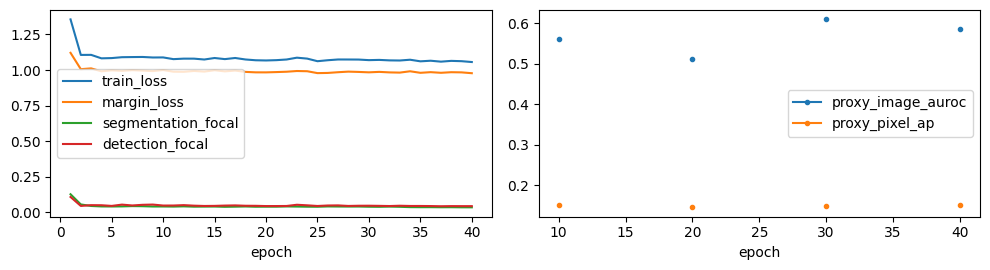

In [6]:
r=json.loads((report/'runs/04-dev-reference_noise-bottle-s2026-v1-result.json').read_text())
common=json.loads((report/'04-common-reference_noise-bottle-s2026-v1.json').read_text())
print(json.dumps(r['configuration'],indent=2));display(pd.DataFrame(common['candidates']).T)
print('Resources:',r['resources'],'adapter relative weight drift:',r['adapter_relative_weight_drift'])
history=pd.DataFrame(r['history'])
fig,axes=plt.subplots(1,2,figsize=(10,2.8))
history.plot(x='epoch',y=['train_loss','margin_loss','segmentation_focal','detection_focal'],ax=axes[0])
history.plot(x='epoch',y=['proxy_image_auroc','proxy_pixel_ap'],marker='.',ax=axes[1]);plt.tight_layout();plt.show();plt.close(fig)


**Measured result and interpretation:** common-proxy best aggregation `head` has image AUROC **0.809750**, pixel AP **0.189969**, objective **0.477877**. The fixed training loop took **88.10s**. Final balanced margin diagnostic was **0.977584**; this remains a diagnostic even when omitted from the focal-only objective. Adapter relative weight drift was **0.034245**. Four-category common-proxy rule selected noise05/top1pct; all unsuccessful trials retained. Decision: **reject**. These synthetic measurements do not establish real-defect quality.


## Experiment 04-dev-reference_noise-cable-s2026-v1: hypothesis before the recorded job
Reference noise is learnable with more fitting normals and the fixed 40-epoch Lite budget. Category **cable**, fixed seed2026, 40 epochs, final checkpoint. Fitting/probe sources are disjoint. This artifact-analysis cell reads the completed [immutable experiment](../experiments/04-dev-reference_noise-cable-s2026-v1-result.json), actual history and common-proxy evaluation. Training-curve proxies use the training magnitude; the final configuration comparison uses identical .05 proxies for every candidate.


{
  "backbone": "resnet18",
  "channels": 384,
  "seg_width": 256,
  "det_width": 32,
  "adapter_trainable": true,
  "noise_std": 0.015,
  "loss": "margin_focal",
  "seed": 2026,
  "batch_size": 8,
  "extraction_batch": 8,
  "epochs": 40,
  "validation_every": 10,
  "hypothesis": "Reference noise is learnable with more fitting normals and the fixed 40-epoch Lite budget"
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,normal_development_q95,objective
head,0.422917,0.500602,0.0,0.0,0.0,0.0,"[[30, 0], [32, 0]]",0.158141,0.298473,0.290529
max,0.495833,0.553309,0.21875,0.2,0.538462,0.311111,"[[24, 6], [25, 7]]",0.158141,0.602315,0.289487
top1pct,0.476042,0.505506,0.03125,0.166667,0.166667,0.052632,"[[25, 5], [31, 1]]",0.158141,0.498385,0.287924


Resources: {'seconds': 92.17630819999613, 'cpu_initial_rss_bytes': 2004807680, 'cpu_peak_rss_bytes': 2283843584, 'cpu_peak_increment_bytes': 279035904, 'cpu_sampling_seconds': 0.05, 'peak_gpu_allocated_bytes': 761477632, 'peak_gpu_reserved_bytes': 947912704} adapter relative weight drift: 0.041254349052906036


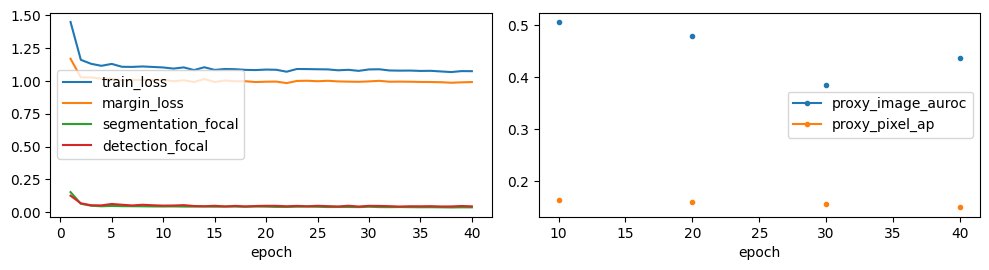

In [7]:
r=json.loads((report/'runs/04-dev-reference_noise-cable-s2026-v1-result.json').read_text())
common=json.loads((report/'04-common-reference_noise-cable-s2026-v1.json').read_text())
print(json.dumps(r['configuration'],indent=2));display(pd.DataFrame(common['candidates']).T)
print('Resources:',r['resources'],'adapter relative weight drift:',r['adapter_relative_weight_drift'])
history=pd.DataFrame(r['history'])
fig,axes=plt.subplots(1,2,figsize=(10,2.8))
history.plot(x='epoch',y=['train_loss','margin_loss','segmentation_focal','detection_focal'],ax=axes[0])
history.plot(x='epoch',y=['proxy_image_auroc','proxy_pixel_ap'],marker='.',ax=axes[1]);plt.tight_layout();plt.show();plt.close(fig)


**Measured result and interpretation:** common-proxy best aggregation `head` has image AUROC **0.422917**, pixel AP **0.158141**, objective **0.290529**. The fixed training loop took **92.18s**. Final balanced margin diagnostic was **0.991931**; this remains a diagnostic even when omitted from the focal-only objective. Adapter relative weight drift was **0.041254**. Four-category common-proxy rule selected noise05/top1pct; all unsuccessful trials retained. Decision: **reject**. These synthetic measurements do not establish real-defect quality.


## Experiment 04-dev-reference_noise-carpet-s2026-v1: hypothesis before the recorded job
Reference noise is learnable with more fitting normals and the fixed 40-epoch Lite budget. Category **carpet**, fixed seed2026, 40 epochs, final checkpoint. Fitting/probe sources are disjoint. This artifact-analysis cell reads the completed [immutable experiment](../experiments/04-dev-reference_noise-carpet-s2026-v1-result.json), actual history and common-proxy evaluation. Training-curve proxies use the training magnitude; the final configuration comparison uses identical .05 proxies for every candidate.


{
  "backbone": "resnet18",
  "channels": 384,
  "seg_width": 256,
  "det_width": 32,
  "adapter_trainable": true,
  "noise_std": 0.015,
  "loss": "margin_focal",
  "seed": 2026,
  "batch_size": 8,
  "extraction_batch": 8,
  "epochs": 40,
  "validation_every": 10,
  "hypothesis": "Reference noise is learnable with more fitting normals and the fixed 40-epoch Lite budget"
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,normal_development_q95,objective
head,1.0,1.0,1.0,0.073171,0.925,0.961039,"[[38, 3], [0, 37]]",0.952624,0.237554,0.970519
max,1.0,1.0,1.0,0.0,1.0,1.0,"[[41, 0], [0, 37]]",0.952624,1.038636,0.976312
top1pct,1.0,1.0,1.0,0.04878,0.948718,0.973684,"[[39, 2], [0, 37]]",0.952624,0.619517,0.976312


Resources: {'seconds': 92.627742699995, 'cpu_initial_rss_bytes': 2076016640, 'cpu_peak_rss_bytes': 2306015232, 'cpu_peak_increment_bytes': 229998592, 'cpu_sampling_seconds': 0.05, 'peak_gpu_allocated_bytes': 761477632, 'peak_gpu_reserved_bytes': 947912704} adapter relative weight drift: 0.08193079382181168


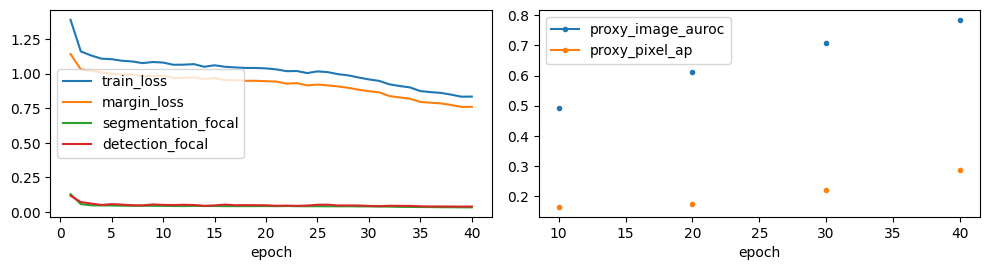

In [8]:
r=json.loads((report/'runs/04-dev-reference_noise-carpet-s2026-v1-result.json').read_text())
common=json.loads((report/'04-common-reference_noise-carpet-s2026-v1.json').read_text())
print(json.dumps(r['configuration'],indent=2));display(pd.DataFrame(common['candidates']).T)
print('Resources:',r['resources'],'adapter relative weight drift:',r['adapter_relative_weight_drift'])
history=pd.DataFrame(r['history'])
fig,axes=plt.subplots(1,2,figsize=(10,2.8))
history.plot(x='epoch',y=['train_loss','margin_loss','segmentation_focal','detection_focal'],ax=axes[0])
history.plot(x='epoch',y=['proxy_image_auroc','proxy_pixel_ap'],marker='.',ax=axes[1]);plt.tight_layout();plt.show();plt.close(fig)


**Measured result and interpretation:** common-proxy best aggregation `max` has image AUROC **1.000000**, pixel AP **0.952624**, objective **0.976312**. The fixed training loop took **92.63s**. Final balanced margin diagnostic was **0.760224**; this remains a diagnostic even when omitted from the focal-only objective. Adapter relative weight drift was **0.081931**. Four-category common-proxy rule selected noise05/top1pct; all unsuccessful trials retained. Decision: **reject**. These synthetic measurements do not establish real-defect quality.


## Experiment 04-dev-reference_noise-tile-s2026-v1: hypothesis before the recorded job
Reference noise is learnable with more fitting normals and the fixed 40-epoch Lite budget. Category **tile**, fixed seed2026, 40 epochs, final checkpoint. Fitting/probe sources are disjoint. This artifact-analysis cell reads the completed [immutable experiment](../experiments/04-dev-reference_noise-tile-s2026-v1-result.json), actual history and common-proxy evaluation. Training-curve proxies use the training magnitude; the final configuration comparison uses identical .05 proxies for every candidate.


{
  "backbone": "resnet18",
  "channels": 384,
  "seg_width": 256,
  "det_width": 32,
  "adapter_trainable": true,
  "noise_std": 0.015,
  "loss": "margin_focal",
  "seed": 2026,
  "batch_size": 8,
  "extraction_batch": 8,
  "epochs": 40,
  "validation_every": 10,
  "hypothesis": "Reference noise is learnable with more fitting normals and the fixed 40-epoch Lite budget"
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,normal_development_q95,objective
head,0.467773,0.508012,0.03125,0.09375,0.25,0.055556,"[[29, 3], [31, 1]]",0.300836,0.29049,0.373367
max,0.859375,0.824875,0.15625,0.03125,0.833333,0.263158,"[[31, 1], [27, 5]]",0.300836,0.667542,0.580105
top1pct,0.871094,0.871903,0.34375,0.03125,0.916667,0.5,"[[31, 1], [21, 11]]",0.300836,0.460645,0.585965


Resources: {'seconds': 91.54501439999876, 'cpu_initial_rss_bytes': 2081124352, 'cpu_peak_rss_bytes': 2277429248, 'cpu_peak_increment_bytes': 196304896, 'cpu_sampling_seconds': 0.05, 'peak_gpu_allocated_bytes': 761477632, 'peak_gpu_reserved_bytes': 947912704} adapter relative weight drift: 0.04530099034309387


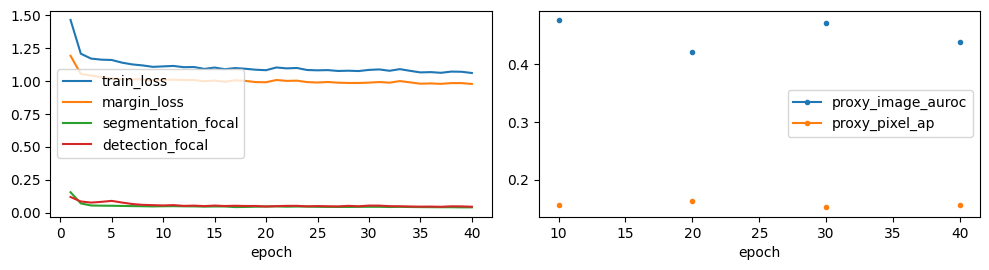

In [9]:
r=json.loads((report/'runs/04-dev-reference_noise-tile-s2026-v1-result.json').read_text())
common=json.loads((report/'04-common-reference_noise-tile-s2026-v1.json').read_text())
print(json.dumps(r['configuration'],indent=2));display(pd.DataFrame(common['candidates']).T)
print('Resources:',r['resources'],'adapter relative weight drift:',r['adapter_relative_weight_drift'])
history=pd.DataFrame(r['history'])
fig,axes=plt.subplots(1,2,figsize=(10,2.8))
history.plot(x='epoch',y=['train_loss','margin_loss','segmentation_focal','detection_focal'],ax=axes[0])
history.plot(x='epoch',y=['proxy_image_auroc','proxy_pixel_ap'],marker='.',ax=axes[1]);plt.tight_layout();plt.show();plt.close(fig)


**Measured result and interpretation:** common-proxy best aggregation `top1pct` has image AUROC **0.871094**, pixel AP **0.300836**, objective **0.585965**. The fixed training loop took **91.55s**. Final balanced margin diagnostic was **0.977526**; this remains a diagnostic even when omitted from the focal-only objective. Adapter relative weight drift was **0.045301**. Four-category common-proxy rule selected noise05/top1pct; all unsuccessful trials retained. Decision: **reject**. These synthetic measurements do not establish real-defect quality.


## Experiment 04-dev-noise05-bottle-s2026-v1: hypothesis before the recorded job
Stronger noise improves synthetic discrimination over the same fixed Lite budget. Category **bottle**, fixed seed2026, 40 epochs, final checkpoint. Fitting/probe sources are disjoint. This artifact-analysis cell reads the completed [immutable experiment](../experiments/04-dev-noise05-bottle-s2026-v1-result.json), actual history and common-proxy evaluation. Training-curve proxies use the training magnitude; the final configuration comparison uses identical .05 proxies for every candidate.


{
  "backbone": "resnet18",
  "channels": 384,
  "seg_width": 256,
  "det_width": 32,
  "adapter_trainable": true,
  "noise_std": 0.05,
  "loss": "margin_focal",
  "seed": 2026,
  "batch_size": 8,
  "extraction_batch": 8,
  "epochs": 40,
  "validation_every": 10,
  "hypothesis": "Stronger noise improves synthetic discrimination over the same fixed Lite budget"
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,normal_development_q95,objective
head,1.0,1.0,1.0,0.206897,0.828571,0.90625,"[[23, 6], [0, 29]]",0.945672,-1.194913,0.933612
max,1.0,1.0,1.0,0.103448,0.90625,0.95082,"[[26, 3], [0, 29]]",0.945672,0.754042,0.959474
top1pct,1.0,1.0,1.0,0.137931,0.878788,0.935484,"[[25, 4], [0, 29]]",0.945672,0.350053,0.950853


Resources: {'seconds': 82.1537468999959, 'cpu_initial_rss_bytes': 2082480128, 'cpu_peak_rss_bytes': 2259767296, 'cpu_peak_increment_bytes': 177287168, 'cpu_sampling_seconds': 0.05, 'peak_gpu_allocated_bytes': 761477632, 'peak_gpu_reserved_bytes': 947912704} adapter relative weight drift: 0.1252131313085556


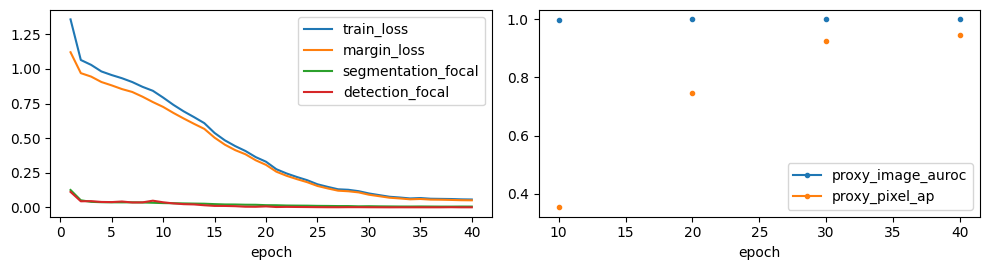

In [10]:
r=json.loads((report/'runs/04-dev-noise05-bottle-s2026-v1-result.json').read_text())
common=json.loads((report/'04-common-noise05-bottle-s2026-v1.json').read_text())
print(json.dumps(r['configuration'],indent=2));display(pd.DataFrame(common['candidates']).T)
print('Resources:',r['resources'],'adapter relative weight drift:',r['adapter_relative_weight_drift'])
history=pd.DataFrame(r['history'])
fig,axes=plt.subplots(1,2,figsize=(10,2.8))
history.plot(x='epoch',y=['train_loss','margin_loss','segmentation_focal','detection_focal'],ax=axes[0])
history.plot(x='epoch',y=['proxy_image_auroc','proxy_pixel_ap'],marker='.',ax=axes[1]);plt.tight_layout();plt.show();plt.close(fig)


**Measured result and interpretation:** common-proxy best aggregation `max` has image AUROC **1.000000**, pixel AP **0.945672**, objective **0.959474**. The fixed training loop took **82.15s**. Final balanced margin diagnostic was **0.050896**; this remains a diagnostic even when omitted from the focal-only objective. Adapter relative weight drift was **0.125213**. Four-category common-proxy rule selected noise05/top1pct; all unsuccessful trials retained. Decision: **select**. These synthetic measurements do not establish real-defect quality.


## Experiment 04-dev-noise05-cable-s2026-v1: hypothesis before the recorded job
Stronger noise improves synthetic discrimination over the same fixed Lite budget. Category **cable**, fixed seed2026, 40 epochs, final checkpoint. Fitting/probe sources are disjoint. This artifact-analysis cell reads the completed [immutable experiment](../experiments/04-dev-noise05-cable-s2026-v1-result.json), actual history and common-proxy evaluation. Training-curve proxies use the training magnitude; the final configuration comparison uses identical .05 proxies for every candidate.


{
  "backbone": "resnet18",
  "channels": 384,
  "seg_width": 256,
  "det_width": 32,
  "adapter_trainable": true,
  "noise_std": 0.05,
  "loss": "margin_focal",
  "seed": 2026,
  "batch_size": 8,
  "extraction_batch": 8,
  "epochs": 40,
  "validation_every": 10,
  "hypothesis": "Stronger noise improves synthetic discrimination over the same fixed Lite budget"
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,normal_development_q95,objective
head,1.0,1.0,1.0,0.0,1.0,1.0,"[[30, 0], [0, 32]]",0.837776,-0.108015,0.918888
max,0.977083,0.98016,0.90625,0.166667,0.852941,0.878788,"[[25, 5], [3, 29]]",0.837776,0.878007,0.878263
top1pct,0.994792,0.995337,0.96875,0.1,0.911765,0.939394,"[[27, 3], [1, 31]]",0.837776,0.551251,0.903784


Resources: {'seconds': 95.3957722999985, 'cpu_initial_rss_bytes': 2067652608, 'cpu_peak_rss_bytes': 2270199808, 'cpu_peak_increment_bytes': 202547200, 'cpu_sampling_seconds': 0.05, 'peak_gpu_allocated_bytes': 761477632, 'peak_gpu_reserved_bytes': 947912704} adapter relative weight drift: 0.12906484305858612


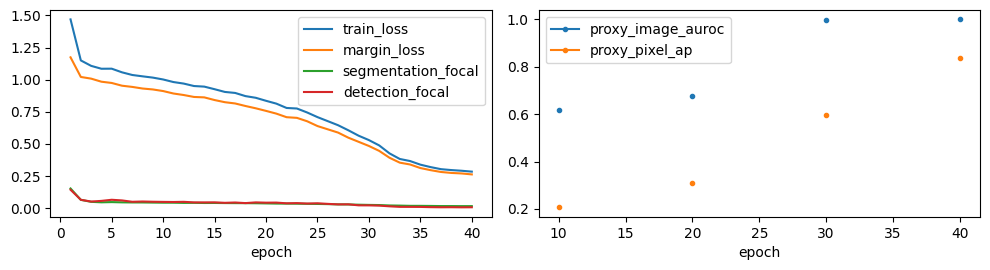

In [11]:
r=json.loads((report/'runs/04-dev-noise05-cable-s2026-v1-result.json').read_text())
common=json.loads((report/'04-common-noise05-cable-s2026-v1.json').read_text())
print(json.dumps(r['configuration'],indent=2));display(pd.DataFrame(common['candidates']).T)
print('Resources:',r['resources'],'adapter relative weight drift:',r['adapter_relative_weight_drift'])
history=pd.DataFrame(r['history'])
fig,axes=plt.subplots(1,2,figsize=(10,2.8))
history.plot(x='epoch',y=['train_loss','margin_loss','segmentation_focal','detection_focal'],ax=axes[0])
history.plot(x='epoch',y=['proxy_image_auroc','proxy_pixel_ap'],marker='.',ax=axes[1]);plt.tight_layout();plt.show();plt.close(fig)


**Measured result and interpretation:** common-proxy best aggregation `head` has image AUROC **1.000000**, pixel AP **0.837776**, objective **0.918888**. The fixed training loop took **95.40s**. Final balanced margin diagnostic was **0.262183**; this remains a diagnostic even when omitted from the focal-only objective. Adapter relative weight drift was **0.129065**. Four-category common-proxy rule selected noise05/top1pct; all unsuccessful trials retained. Decision: **select**. These synthetic measurements do not establish real-defect quality.


## Experiment 04-dev-noise05-carpet-s2026-v1: hypothesis before the recorded job
Stronger noise improves synthetic discrimination over the same fixed Lite budget. Category **carpet**, fixed seed2026, 40 epochs, final checkpoint. Fitting/probe sources are disjoint. This artifact-analysis cell reads the completed [immutable experiment](../experiments/04-dev-noise05-carpet-s2026-v1-result.json), actual history and common-proxy evaluation. Training-curve proxies use the training magnitude; the final configuration comparison uses identical .05 proxies for every candidate.


{
  "backbone": "resnet18",
  "channels": 384,
  "seg_width": 256,
  "det_width": 32,
  "adapter_trainable": true,
  "noise_std": 0.05,
  "loss": "margin_focal",
  "seed": 2026,
  "batch_size": 8,
  "extraction_batch": 8,
  "epochs": 40,
  "validation_every": 10,
  "hypothesis": "Stronger noise improves synthetic discrimination over the same fixed Lite budget"
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,normal_development_q95,objective
head,1.0,1.0,1.0,0.097561,0.902439,0.948718,"[[37, 4], [0, 37]]",0.970714,-1.291172,0.973467
max,1.0,1.0,1.0,0.073171,0.925,0.961039,"[[38, 3], [0, 37]]",0.970714,-0.050746,0.979564
top1pct,1.0,1.0,1.0,0.04878,0.948718,0.973684,"[[39, 2], [0, 37]]",0.970714,-0.324813,0.985357


Resources: {'seconds': 112.93606790000194, 'cpu_initial_rss_bytes': 2081959936, 'cpu_peak_rss_bytes': 2294018048, 'cpu_peak_increment_bytes': 212058112, 'cpu_sampling_seconds': 0.05, 'peak_gpu_allocated_bytes': 761477632, 'peak_gpu_reserved_bytes': 947912704} adapter relative weight drift: 0.12035423517227173


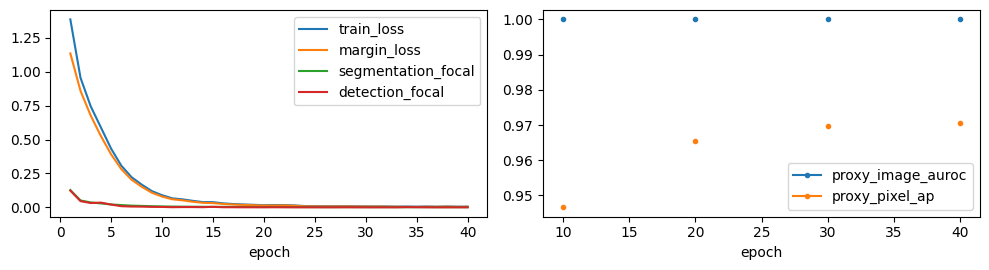

In [12]:
r=json.loads((report/'runs/04-dev-noise05-carpet-s2026-v1-result.json').read_text())
common=json.loads((report/'04-common-noise05-carpet-s2026-v1.json').read_text())
print(json.dumps(r['configuration'],indent=2));display(pd.DataFrame(common['candidates']).T)
print('Resources:',r['resources'],'adapter relative weight drift:',r['adapter_relative_weight_drift'])
history=pd.DataFrame(r['history'])
fig,axes=plt.subplots(1,2,figsize=(10,2.8))
history.plot(x='epoch',y=['train_loss','margin_loss','segmentation_focal','detection_focal'],ax=axes[0])
history.plot(x='epoch',y=['proxy_image_auroc','proxy_pixel_ap'],marker='.',ax=axes[1]);plt.tight_layout();plt.show();plt.close(fig)


**Measured result and interpretation:** common-proxy best aggregation `top1pct` has image AUROC **1.000000**, pixel AP **0.970714**, objective **0.985357**. The fixed training loop took **112.94s**. Final balanced margin diagnostic was **0.003945**; this remains a diagnostic even when omitted from the focal-only objective. Adapter relative weight drift was **0.120354**. Four-category common-proxy rule selected noise05/top1pct; all unsuccessful trials retained. Decision: **select**. These synthetic measurements do not establish real-defect quality.


## Experiment 04-dev-noise05-tile-s2026-v1: hypothesis before the recorded job
Stronger noise improves synthetic discrimination over the same fixed Lite budget. Category **tile**, fixed seed2026, 40 epochs, final checkpoint. Fitting/probe sources are disjoint. This artifact-analysis cell reads the completed [immutable experiment](../experiments/04-dev-noise05-tile-s2026-v1-result.json), actual history and common-proxy evaluation. Training-curve proxies use the training magnitude; the final configuration comparison uses identical .05 proxies for every candidate.


{
  "backbone": "resnet18",
  "channels": 384,
  "seg_width": 256,
  "det_width": 32,
  "adapter_trainable": true,
  "noise_std": 0.05,
  "loss": "margin_focal",
  "seed": 2026,
  "batch_size": 8,
  "extraction_batch": 8,
  "epochs": 40,
  "validation_every": 10,
  "hypothesis": "Stronger noise improves synthetic discrimination over the same fixed Lite budget"
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,normal_development_q95,objective
head,1.0,1.0,1.0,0.09375,0.914286,0.955224,"[[29, 3], [0, 32]]",0.965032,-1.04996,0.971578
max,1.0,1.0,1.0,0.1875,0.842105,0.914286,"[[26, 6], [0, 32]]",0.965032,0.07807,0.948141
top1pct,1.0,1.0,1.0,0.0625,0.941176,0.969697,"[[30, 2], [0, 32]]",0.965032,-0.165735,0.979391


Resources: {'seconds': 95.02789750000375, 'cpu_initial_rss_bytes': 2080882688, 'cpu_peak_rss_bytes': 2272387072, 'cpu_peak_increment_bytes': 191504384, 'cpu_sampling_seconds': 0.05, 'peak_gpu_allocated_bytes': 761477632, 'peak_gpu_reserved_bytes': 947912704} adapter relative weight drift: 0.13726721704006195


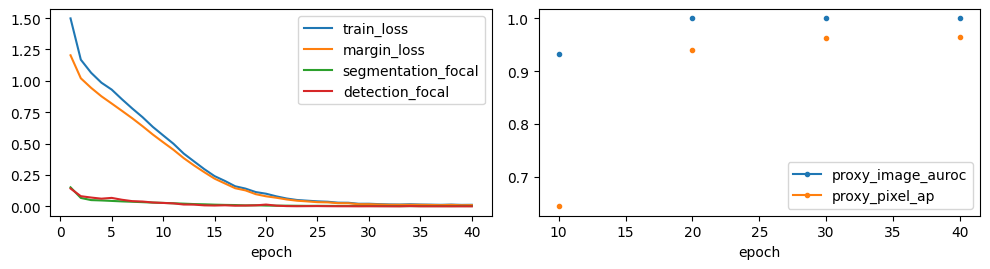

In [13]:
r=json.loads((report/'runs/04-dev-noise05-tile-s2026-v1-result.json').read_text())
common=json.loads((report/'04-common-noise05-tile-s2026-v1.json').read_text())
print(json.dumps(r['configuration'],indent=2));display(pd.DataFrame(common['candidates']).T)
print('Resources:',r['resources'],'adapter relative weight drift:',r['adapter_relative_weight_drift'])
history=pd.DataFrame(r['history'])
fig,axes=plt.subplots(1,2,figsize=(10,2.8))
history.plot(x='epoch',y=['train_loss','margin_loss','segmentation_focal','detection_focal'],ax=axes[0])
history.plot(x='epoch',y=['proxy_image_auroc','proxy_pixel_ap'],marker='.',ax=axes[1]);plt.tight_layout();plt.show();plt.close(fig)


**Measured result and interpretation:** common-proxy best aggregation `top1pct` has image AUROC **1.000000**, pixel AP **0.965032**, objective **0.979391**. The fixed training loop took **95.03s**. Final balanced margin diagnostic was **0.009927**; this remains a diagnostic even when omitted from the focal-only objective. Adapter relative weight drift was **0.137267**. Four-category common-proxy rule selected noise05/top1pct; all unsuccessful trials retained. Decision: **select**. These synthetic measurements do not establish real-defect quality.


## Experiment 04-dev-frozen_adapter-bottle-s2026-v1: hypothesis before the recorded job
Freezing the random adapter tests whether adaptation improves stable discrimination. Category **bottle**, fixed seed2026, 40 epochs, final checkpoint. Fitting/probe sources are disjoint. This artifact-analysis cell reads the completed [immutable experiment](../experiments/04-dev-frozen_adapter-bottle-s2026-v1-result.json), actual history and common-proxy evaluation. Training-curve proxies use the training magnitude; the final configuration comparison uses identical .05 proxies for every candidate.


{
  "backbone": "resnet18",
  "channels": 384,
  "seg_width": 256,
  "det_width": 32,
  "adapter_trainable": false,
  "noise_std": 0.015,
  "loss": "margin_focal",
  "seed": 2026,
  "batch_size": 8,
  "extraction_batch": 8,
  "epochs": 40,
  "validation_every": 10,
  "hypothesis": "Freezing the random adapter tests whether adaptation improves stable discrimination"
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,normal_development_q95,objective
head,0.627824,0.660321,0.448276,0.137931,0.764706,0.565217,"[[25, 4], [16, 13]]",0.181933,0.096497,0.382896
max,0.545779,0.50912,0.034483,0.034483,0.5,0.064516,"[[28, 1], [28, 1]]",0.181933,0.559397,0.363856
top1pct,0.530321,0.500748,0.034483,0.103448,0.25,0.060606,"[[26, 3], [28, 1]]",0.181933,0.401792,0.342765


Resources: {'seconds': 73.05903780000517, 'cpu_initial_rss_bytes': 2082062336, 'cpu_peak_rss_bytes': 2279821312, 'cpu_peak_increment_bytes': 197758976, 'cpu_sampling_seconds': 0.05, 'peak_gpu_allocated_bytes': 700365824, 'peak_gpu_reserved_bytes': 947912704} adapter relative weight drift: 0.0


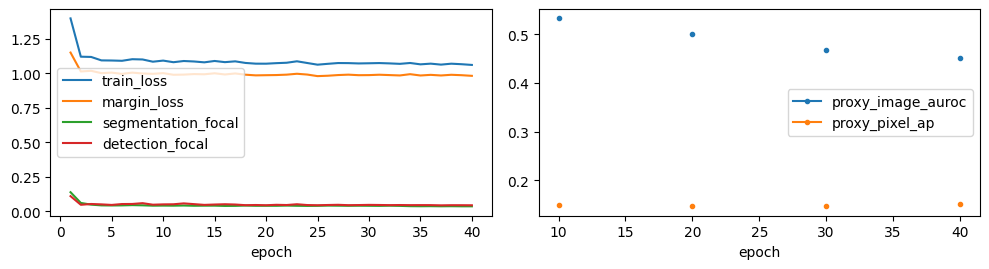

In [14]:
r=json.loads((report/'runs/04-dev-frozen_adapter-bottle-s2026-v1-result.json').read_text())
common=json.loads((report/'04-common-frozen_adapter-bottle-s2026-v1.json').read_text())
print(json.dumps(r['configuration'],indent=2));display(pd.DataFrame(common['candidates']).T)
print('Resources:',r['resources'],'adapter relative weight drift:',r['adapter_relative_weight_drift'])
history=pd.DataFrame(r['history'])
fig,axes=plt.subplots(1,2,figsize=(10,2.8))
history.plot(x='epoch',y=['train_loss','margin_loss','segmentation_focal','detection_focal'],ax=axes[0])
history.plot(x='epoch',y=['proxy_image_auroc','proxy_pixel_ap'],marker='.',ax=axes[1]);plt.tight_layout();plt.show();plt.close(fig)


**Measured result and interpretation:** common-proxy best aggregation `head` has image AUROC **0.627824**, pixel AP **0.181933**, objective **0.382896**. The fixed training loop took **73.06s**. Final balanced margin diagnostic was **0.980302**; this remains a diagnostic even when omitted from the focal-only objective. Adapter relative weight drift was **0.000000**. Four-category common-proxy rule selected noise05/top1pct; all unsuccessful trials retained. Decision: **reject**. These synthetic measurements do not establish real-defect quality.


## Experiment 04-dev-frozen_adapter-cable-s2026-v1: hypothesis before the recorded job
Freezing the random adapter tests whether adaptation improves stable discrimination. Category **cable**, fixed seed2026, 40 epochs, final checkpoint. Fitting/probe sources are disjoint. This artifact-analysis cell reads the completed [immutable experiment](../experiments/04-dev-frozen_adapter-cable-s2026-v1-result.json), actual history and common-proxy evaluation. Training-curve proxies use the training magnitude; the final configuration comparison uses identical .05 proxies for every candidate.


{
  "backbone": "resnet18",
  "channels": 384,
  "seg_width": 256,
  "det_width": 32,
  "adapter_trainable": false,
  "noise_std": 0.015,
  "loss": "margin_focal",
  "seed": 2026,
  "batch_size": 8,
  "extraction_batch": 8,
  "epochs": 40,
  "validation_every": 10,
  "hypothesis": "Freezing the random adapter tests whether adaptation improves stable discrimination"
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,normal_development_q95,objective
head,0.44375,0.513551,0.0625,0.066667,0.5,0.111111,"[[28, 2], [30, 2]]",0.156526,0.199136,0.295971
max,0.499479,0.510311,0.03125,0.1,0.25,0.055556,"[[27, 3], [31, 1]]",0.156526,0.689229,0.315502
top1pct,0.483333,0.495561,0.03125,0.1,0.25,0.055556,"[[27, 3], [31, 1]]",0.156526,0.524582,0.30743


Resources: {'seconds': 89.79615749999357, 'cpu_initial_rss_bytes': 2067611648, 'cpu_peak_rss_bytes': 2295443456, 'cpu_peak_increment_bytes': 227831808, 'cpu_sampling_seconds': 0.05, 'peak_gpu_allocated_bytes': 700365824, 'peak_gpu_reserved_bytes': 947912704} adapter relative weight drift: 0.0


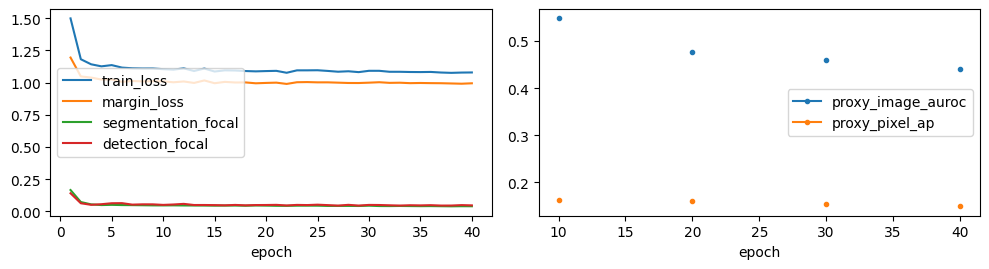

In [15]:
r=json.loads((report/'runs/04-dev-frozen_adapter-cable-s2026-v1-result.json').read_text())
common=json.loads((report/'04-common-frozen_adapter-cable-s2026-v1.json').read_text())
print(json.dumps(r['configuration'],indent=2));display(pd.DataFrame(common['candidates']).T)
print('Resources:',r['resources'],'adapter relative weight drift:',r['adapter_relative_weight_drift'])
history=pd.DataFrame(r['history'])
fig,axes=plt.subplots(1,2,figsize=(10,2.8))
history.plot(x='epoch',y=['train_loss','margin_loss','segmentation_focal','detection_focal'],ax=axes[0])
history.plot(x='epoch',y=['proxy_image_auroc','proxy_pixel_ap'],marker='.',ax=axes[1]);plt.tight_layout();plt.show();plt.close(fig)


**Measured result and interpretation:** common-proxy best aggregation `max` has image AUROC **0.499479**, pixel AP **0.156526**, objective **0.315502**. The fixed training loop took **89.80s**. Final balanced margin diagnostic was **0.994059**; this remains a diagnostic even when omitted from the focal-only objective. Adapter relative weight drift was **0.000000**. Four-category common-proxy rule selected noise05/top1pct; all unsuccessful trials retained. Decision: **reject**. These synthetic measurements do not establish real-defect quality.


## Experiment 04-dev-frozen_adapter-carpet-s2026-v1: hypothesis before the recorded job
Freezing the random adapter tests whether adaptation improves stable discrimination. Category **carpet**, fixed seed2026, 40 epochs, final checkpoint. Fitting/probe sources are disjoint. This artifact-analysis cell reads the completed [immutable experiment](../experiments/04-dev-frozen_adapter-carpet-s2026-v1-result.json), actual history and common-proxy evaluation. Training-curve proxies use the training magnitude; the final configuration comparison uses identical .05 proxies for every candidate.


{
  "backbone": "resnet18",
  "channels": 384,
  "seg_width": 256,
  "det_width": 32,
  "adapter_trainable": false,
  "noise_std": 0.015,
  "loss": "margin_focal",
  "seed": 2026,
  "batch_size": 8,
  "extraction_batch": 8,
  "epochs": 40,
  "validation_every": 10,
  "hypothesis": "Freezing the random adapter tests whether adaptation improves stable discrimination"
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,normal_development_q95,objective
head,0.73764,0.734711,0.351351,0.073171,0.8125,0.490566,"[[38, 3], [24, 13]]",0.819811,0.34193,0.772933
max,0.998022,0.997808,0.918919,0.02439,0.971429,0.944444,"[[40, 1], [3, 34]]",0.819811,0.901516,0.908916
top1pct,1.0,1.0,1.0,0.0,1.0,1.0,"[[41, 0], [0, 37]]",0.819811,0.582351,0.909905


Resources: {'seconds': 116.00141579999763, 'cpu_initial_rss_bytes': 2080432128, 'cpu_peak_rss_bytes': 2332573696, 'cpu_peak_increment_bytes': 252141568, 'cpu_sampling_seconds': 0.05, 'peak_gpu_allocated_bytes': 700365824, 'peak_gpu_reserved_bytes': 947912704} adapter relative weight drift: 0.0


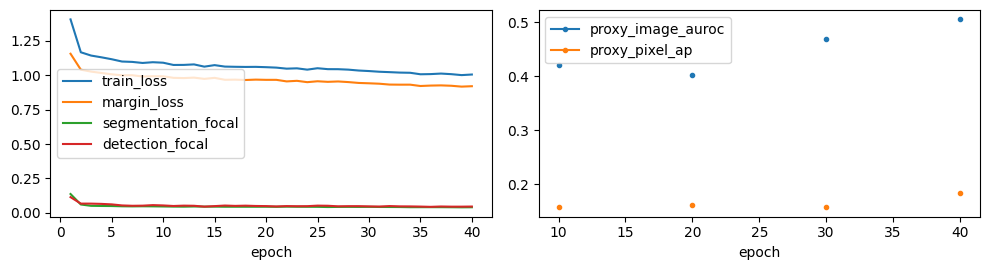

In [16]:
r=json.loads((report/'runs/04-dev-frozen_adapter-carpet-s2026-v1-result.json').read_text())
common=json.loads((report/'04-common-frozen_adapter-carpet-s2026-v1.json').read_text())
print(json.dumps(r['configuration'],indent=2));display(pd.DataFrame(common['candidates']).T)
print('Resources:',r['resources'],'adapter relative weight drift:',r['adapter_relative_weight_drift'])
history=pd.DataFrame(r['history'])
fig,axes=plt.subplots(1,2,figsize=(10,2.8))
history.plot(x='epoch',y=['train_loss','margin_loss','segmentation_focal','detection_focal'],ax=axes[0])
history.plot(x='epoch',y=['proxy_image_auroc','proxy_pixel_ap'],marker='.',ax=axes[1]);plt.tight_layout();plt.show();plt.close(fig)


**Measured result and interpretation:** common-proxy best aggregation `top1pct` has image AUROC **1.000000**, pixel AP **0.819811**, objective **0.909905**. The fixed training loop took **116.00s**. Final balanced margin diagnostic was **0.920904**; this remains a diagnostic even when omitted from the focal-only objective. Adapter relative weight drift was **0.000000**. Four-category common-proxy rule selected noise05/top1pct; all unsuccessful trials retained. Decision: **reject**. These synthetic measurements do not establish real-defect quality.


## Experiment 04-dev-frozen_adapter-tile-s2026-v1: hypothesis before the recorded job
Freezing the random adapter tests whether adaptation improves stable discrimination. Category **tile**, fixed seed2026, 40 epochs, final checkpoint. Fitting/probe sources are disjoint. This artifact-analysis cell reads the completed [immutable experiment](../experiments/04-dev-frozen_adapter-tile-s2026-v1-result.json), actual history and common-proxy evaluation. Training-curve proxies use the training magnitude; the final configuration comparison uses identical .05 proxies for every candidate.


{
  "backbone": "resnet18",
  "channels": 384,
  "seg_width": 256,
  "det_width": 32,
  "adapter_trainable": false,
  "noise_std": 0.015,
  "loss": "margin_focal",
  "seed": 2026,
  "batch_size": 8,
  "extraction_batch": 8,
  "epochs": 40,
  "validation_every": 10,
  "hypothesis": "Freezing the random adapter tests whether adaptation improves stable discrimination"
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,normal_development_q95,objective
head,0.426758,0.448562,0.0,0.03125,0.0,0.0,"[[31, 1], [32, 0]]",0.235289,0.422822,0.331023
max,0.801758,0.755836,0.0625,0.03125,0.666667,0.114286,"[[31, 1], [30, 2]]",0.235289,0.739012,0.518523
top1pct,0.786133,0.782636,0.1875,0.03125,0.857143,0.307692,"[[31, 1], [26, 6]]",0.235289,0.501964,0.510711


Resources: {'seconds': 88.79991479999444, 'cpu_initial_rss_bytes': 2081837056, 'cpu_peak_rss_bytes': 2279784448, 'cpu_peak_increment_bytes': 197947392, 'cpu_sampling_seconds': 0.05, 'peak_gpu_allocated_bytes': 700365824, 'peak_gpu_reserved_bytes': 947912704} adapter relative weight drift: 0.0


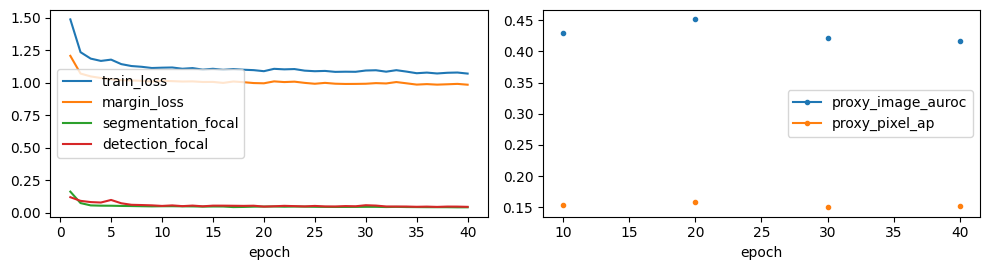

In [17]:
r=json.loads((report/'runs/04-dev-frozen_adapter-tile-s2026-v1-result.json').read_text())
common=json.loads((report/'04-common-frozen_adapter-tile-s2026-v1.json').read_text())
print(json.dumps(r['configuration'],indent=2));display(pd.DataFrame(common['candidates']).T)
print('Resources:',r['resources'],'adapter relative weight drift:',r['adapter_relative_weight_drift'])
history=pd.DataFrame(r['history'])
fig,axes=plt.subplots(1,2,figsize=(10,2.8))
history.plot(x='epoch',y=['train_loss','margin_loss','segmentation_focal','detection_focal'],ax=axes[0])
history.plot(x='epoch',y=['proxy_image_auroc','proxy_pixel_ap'],marker='.',ax=axes[1]);plt.tight_layout();plt.show();plt.close(fig)


**Measured result and interpretation:** common-proxy best aggregation `max` has image AUROC **0.801758**, pixel AP **0.235289**, objective **0.518523**. The fixed training loop took **88.80s**. Final balanced margin diagnostic was **0.985203**; this remains a diagnostic even when omitted from the focal-only objective. Adapter relative weight drift was **0.000000**. Four-category common-proxy rule selected noise05/top1pct; all unsuccessful trials retained. Decision: **reject**. These synthetic measurements do not establish real-defect quality.


## Experiment 04-dev-focal_only-bottle-s2026-v1: hypothesis before the recorded job
Removing the balanced margin tests whether it impedes short-budget segmentation learning. Category **bottle**, fixed seed2026, 40 epochs, final checkpoint. Fitting/probe sources are disjoint. This artifact-analysis cell reads the completed [immutable experiment](../experiments/04-dev-focal_only-bottle-s2026-v1-result.json), actual history and common-proxy evaluation. Training-curve proxies use the training magnitude; the final configuration comparison uses identical .05 proxies for every candidate.


{
  "backbone": "resnet18",
  "channels": 384,
  "seg_width": 256,
  "det_width": 32,
  "adapter_trainable": true,
  "noise_std": 0.015,
  "loss": "focal",
  "seed": 2026,
  "batch_size": 8,
  "extraction_batch": 8,
  "epochs": 40,
  "validation_every": 10,
  "hypothesis": "Removing the balanced margin tests whether it impedes short-budget segmentation learning"
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,normal_development_q95,objective
head,0.768133,0.750161,0.62069,0.206897,0.75,0.679245,"[[23, 6], [11, 18]]",0.22029,0.096966,0.454988
max,0.712247,0.705586,0.310345,0.103448,0.75,0.439024,"[[26, 3], [20, 9]]",0.22029,-0.030832,0.452907
top1pct,0.717004,0.685264,0.206897,0.137931,0.6,0.307692,"[[25, 4], [23, 6]]",0.22029,-0.121691,0.446664


Resources: {'seconds': 88.03880270000082, 'cpu_initial_rss_bytes': 2082328576, 'cpu_peak_rss_bytes': 2262515712, 'cpu_peak_increment_bytes': 180187136, 'cpu_sampling_seconds': 0.05, 'peak_gpu_allocated_bytes': 761477632, 'peak_gpu_reserved_bytes': 947912704} adapter relative weight drift: 0.02295110747218132


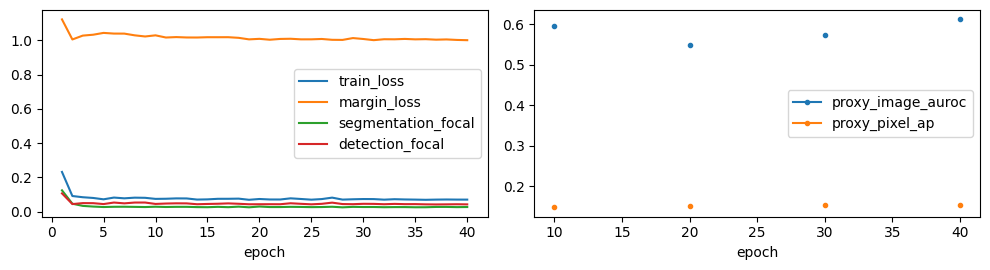

In [18]:
r=json.loads((report/'runs/04-dev-focal_only-bottle-s2026-v1-result.json').read_text())
common=json.loads((report/'04-common-focal_only-bottle-s2026-v1.json').read_text())
print(json.dumps(r['configuration'],indent=2));display(pd.DataFrame(common['candidates']).T)
print('Resources:',r['resources'],'adapter relative weight drift:',r['adapter_relative_weight_drift'])
history=pd.DataFrame(r['history'])
fig,axes=plt.subplots(1,2,figsize=(10,2.8))
history.plot(x='epoch',y=['train_loss','margin_loss','segmentation_focal','detection_focal'],ax=axes[0])
history.plot(x='epoch',y=['proxy_image_auroc','proxy_pixel_ap'],marker='.',ax=axes[1]);plt.tight_layout();plt.show();plt.close(fig)


**Measured result and interpretation:** common-proxy best aggregation `head` has image AUROC **0.768133**, pixel AP **0.220290**, objective **0.454988**. The fixed training loop took **88.04s**. Final balanced margin diagnostic was **1.001171**; this remains a diagnostic even when omitted from the focal-only objective. Adapter relative weight drift was **0.022951**. Four-category common-proxy rule selected noise05/top1pct; all unsuccessful trials retained. Decision: **reject**. These synthetic measurements do not establish real-defect quality.


## Experiment 04-dev-focal_only-cable-s2026-v2: hypothesis before the recorded job
Removing the balanced margin tests whether it impedes short-budget segmentation learning. Category **cable**, fixed seed2026, 40 epochs, final checkpoint. Fitting/probe sources are disjoint. This artifact-analysis cell reads the completed [immutable experiment](../experiments/04-dev-focal_only-cable-s2026-v2-result.json), actual history and common-proxy evaluation. Training-curve proxies use the training magnitude; the final configuration comparison uses identical .05 proxies for every candidate.


{
  "backbone": "resnet18",
  "channels": 384,
  "seg_width": 256,
  "det_width": 32,
  "adapter_trainable": true,
  "noise_std": 0.015,
  "loss": "focal",
  "seed": 2026,
  "batch_size": 8,
  "extraction_batch": 8,
  "epochs": 40,
  "validation_every": 10,
  "hypothesis": "Removing the balanced margin tests whether it impedes short-budget segmentation learning"
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,normal_development_q95,objective
head,0.472917,0.525048,0.03125,0.033333,0.5,0.058824,"[[29, 1], [31, 1]]",0.155175,0.212581,0.314046
max,0.431771,0.496398,0.03125,0.0,1.0,0.060606,"[[30, 0], [31, 1]]",0.155175,0.090149,0.293473
top1pct,0.410417,0.500063,0.03125,0.0,1.0,0.060606,"[[30, 0], [31, 1]]",0.155175,-0.025072,0.282796


Resources: {'seconds': 90.11806290000095, 'cpu_initial_rss_bytes': 895778816, 'cpu_peak_rss_bytes': 1988820992, 'cpu_peak_increment_bytes': 1093042176, 'cpu_sampling_seconds': 0.05, 'peak_gpu_allocated_bytes': 761477632, 'peak_gpu_reserved_bytes': 968884224} adapter relative weight drift: 0.026670735329389572


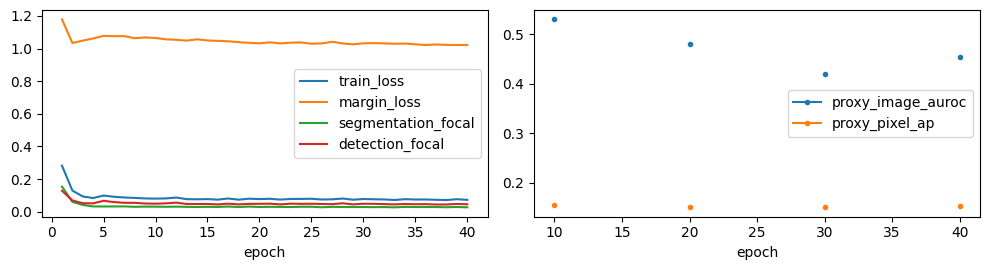

In [19]:
r=json.loads((report/'runs/04-dev-focal_only-cable-s2026-v2-result.json').read_text())
common=json.loads((report/'04-common-focal_only-cable-s2026-v1.json').read_text())
print(json.dumps(r['configuration'],indent=2));display(pd.DataFrame(common['candidates']).T)
print('Resources:',r['resources'],'adapter relative weight drift:',r['adapter_relative_weight_drift'])
history=pd.DataFrame(r['history'])
fig,axes=plt.subplots(1,2,figsize=(10,2.8))
history.plot(x='epoch',y=['train_loss','margin_loss','segmentation_focal','detection_focal'],ax=axes[0])
history.plot(x='epoch',y=['proxy_image_auroc','proxy_pixel_ap'],marker='.',ax=axes[1]);plt.tight_layout();plt.show();plt.close(fig)


**Measured result and interpretation:** common-proxy best aggregation `head` has image AUROC **0.472917**, pixel AP **0.155175**, objective **0.314046**. The fixed training loop took **90.12s**. Final balanced margin diagnostic was **1.022331**; this remains a diagnostic even when omitted from the focal-only objective. Adapter relative weight drift was **0.026671**. Four-category common-proxy rule selected noise05/top1pct; all unsuccessful trials retained. Decision: **reject**. These synthetic measurements do not establish real-defect quality.


## Experiment 04-dev-focal_only-carpet-s2026-v1: hypothesis before the recorded job
Removing the balanced margin tests whether it impedes short-budget segmentation learning. Category **carpet**, fixed seed2026, 40 epochs, final checkpoint. Fitting/probe sources are disjoint. This artifact-analysis cell reads the completed [immutable experiment](../experiments/04-dev-focal_only-carpet-s2026-v1-result.json), actual history and common-proxy evaluation. Training-curve proxies use the training magnitude; the final configuration comparison uses identical .05 proxies for every candidate.


{
  "backbone": "resnet18",
  "channels": 384,
  "seg_width": 256,
  "det_width": 32,
  "adapter_trainable": true,
  "noise_std": 0.015,
  "loss": "focal",
  "seed": 2026,
  "batch_size": 8,
  "extraction_batch": 8,
  "epochs": 40,
  "validation_every": 10,
  "hypothesis": "Removing the balanced margin tests whether it impedes short-budget segmentation learning"
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,normal_development_q95,objective
head,0.662492,0.604962,0.486486,0.146341,0.75,0.590164,"[[35, 6], [19, 18]]",0.36836,0.211809,0.49134
max,0.922874,0.872104,0.351351,0.04878,0.866667,0.5,"[[39, 2], [24, 13]]",0.36836,0.03144,0.645617
top1pct,0.936058,0.926414,0.675676,0.073171,0.892857,0.769231,"[[38, 3], [12, 25]]",0.36836,-0.103596,0.646416


Resources: {'seconds': 112.72461569999723, 'cpu_initial_rss_bytes': 1805209600, 'cpu_peak_rss_bytes': 2049167360, 'cpu_peak_increment_bytes': 243957760, 'cpu_sampling_seconds': 0.05, 'peak_gpu_allocated_bytes': 761477632, 'peak_gpu_reserved_bytes': 973078528} adapter relative weight drift: 0.02683383598923683


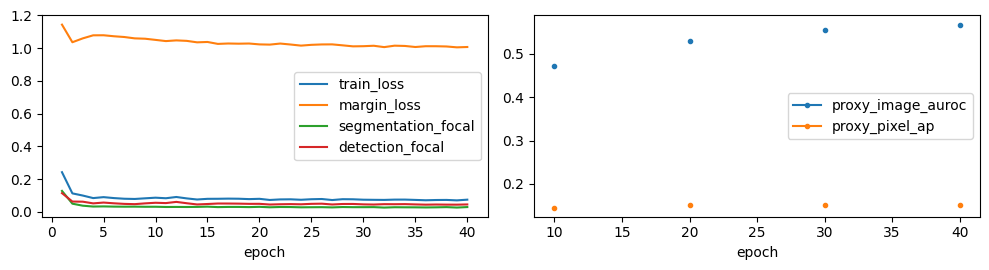

In [20]:
r=json.loads((report/'runs/04-dev-focal_only-carpet-s2026-v1-result.json').read_text())
common=json.loads((report/'04-common-focal_only-carpet-s2026-v1.json').read_text())
print(json.dumps(r['configuration'],indent=2));display(pd.DataFrame(common['candidates']).T)
print('Resources:',r['resources'],'adapter relative weight drift:',r['adapter_relative_weight_drift'])
history=pd.DataFrame(r['history'])
fig,axes=plt.subplots(1,2,figsize=(10,2.8))
history.plot(x='epoch',y=['train_loss','margin_loss','segmentation_focal','detection_focal'],ax=axes[0])
history.plot(x='epoch',y=['proxy_image_auroc','proxy_pixel_ap'],marker='.',ax=axes[1]);plt.tight_layout();plt.show();plt.close(fig)


**Measured result and interpretation:** common-proxy best aggregation `top1pct` has image AUROC **0.936058**, pixel AP **0.368360**, objective **0.646416**. The fixed training loop took **112.72s**. Final balanced margin diagnostic was **1.007453**; this remains a diagnostic even when omitted from the focal-only objective. Adapter relative weight drift was **0.026834**. Four-category common-proxy rule selected noise05/top1pct; all unsuccessful trials retained. Decision: **reject**. These synthetic measurements do not establish real-defect quality.


## Experiment 04-dev-focal_only-tile-s2026-v1: hypothesis before the recorded job
Removing the balanced margin tests whether it impedes short-budget segmentation learning. Category **tile**, fixed seed2026, 40 epochs, final checkpoint. Fitting/probe sources are disjoint. This artifact-analysis cell reads the completed [immutable experiment](../experiments/04-dev-focal_only-tile-s2026-v1-result.json), actual history and common-proxy evaluation. Training-curve proxies use the training magnitude; the final configuration comparison uses identical .05 proxies for every candidate.


{
  "backbone": "resnet18",
  "channels": 384,
  "seg_width": 256,
  "det_width": 32,
  "adapter_trainable": true,
  "noise_std": 0.015,
  "loss": "focal",
  "seed": 2026,
  "batch_size": 8,
  "extraction_batch": 8,
  "epochs": 40,
  "validation_every": 10,
  "hypothesis": "Removing the balanced margin tests whether it impedes short-budget segmentation learning"
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,normal_development_q95,objective
head,0.533203,0.563067,0.0,0.0,0.0,0.0,"[[32, 0], [32, 0]]",0.148988,0.39096,0.341095
max,0.644531,0.617996,0.03125,0.0,1.0,0.060606,"[[32, 0], [31, 1]]",0.148988,0.166213,0.396759
top1pct,0.616211,0.621932,0.15625,0.09375,0.625,0.25,"[[29, 3], [27, 5]]",0.148988,-0.026557,0.371662


Resources: {'seconds': 96.84501029999956, 'cpu_initial_rss_bytes': 1816047616, 'cpu_peak_rss_bytes': 2086817792, 'cpu_peak_increment_bytes': 270770176, 'cpu_sampling_seconds': 0.05, 'peak_gpu_allocated_bytes': 761477632, 'peak_gpu_reserved_bytes': 973078528} adapter relative weight drift: 0.027245229110121727


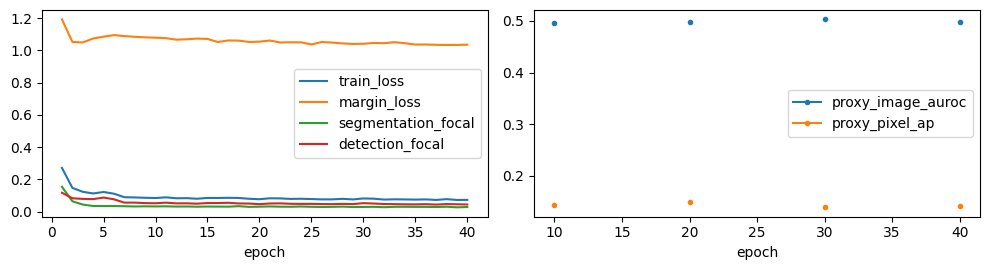

In [21]:
r=json.loads((report/'runs/04-dev-focal_only-tile-s2026-v1-result.json').read_text())
common=json.loads((report/'04-common-focal_only-tile-s2026-v1.json').read_text())
print(json.dumps(r['configuration'],indent=2));display(pd.DataFrame(common['candidates']).T)
print('Resources:',r['resources'],'adapter relative weight drift:',r['adapter_relative_weight_drift'])
history=pd.DataFrame(r['history'])
fig,axes=plt.subplots(1,2,figsize=(10,2.8))
history.plot(x='epoch',y=['train_loss','margin_loss','segmentation_focal','detection_focal'],ax=axes[0])
history.plot(x='epoch',y=['proxy_image_auroc','proxy_pixel_ap'],marker='.',ax=axes[1]);plt.tight_layout();plt.show();plt.close(fig)


**Measured result and interpretation:** common-proxy best aggregation `max` has image AUROC **0.644531**, pixel AP **0.148988**, objective **0.396759**. The fixed training loop took **96.85s**. Final balanced margin diagnostic was **1.035381**; this remains a diagnostic even when omitted from the focal-only objective. Adapter relative weight drift was **0.027245**. Four-category common-proxy rule selected noise05/top1pct; all unsuccessful trials retained. Decision: **reject**. These synthetic measurements do not establish real-defect quality.


## Common-proxy selection and measured execution gate
The registered small study ended after its predefined16 trials. Reference width was rejected by the pilot compute gate, not by official defect scores. Compare common noise/masks and every planned image aggregation. Within .005 of the best objective, prefer lower training time then parameters. Freeze all model, training, preprocessing, scoring and calibration settings before any official test access. Seed count follows measured training cost and is explicit below.


In [22]:
display(pd.read_csv(report/'development_macro.csv'))
display(pd.read_csv(report/'development_common_proxy.csv'))
print(json.dumps(frozen,indent=2))
print(json.dumps(json.loads((report/'compute_budget.json').read_text()),indent=2))
assert sha256(ROOT/'configs/supersimplenet_frozen.json')==summary['frozen_configuration_sha256']
print('Source identities verified:',all(sha256(ROOT/p)==h for p,h in frozen['source_sha256'].items()))


,candidate,aggregation,train_seconds,parameters,auroc,ap,recall,fpr,precision,f1,pixel_ap,normal_development_q95,objective
0,noise05,top1pct,88.976389,555331.0,0.998698,0.998834,0.992188,0.087303,0.920112,0.954565,0.929798,0.102689,0.954846
1,noise05,head,88.976389,555331.0,1.000000,1.000000,1.000000,0.099552,0.911324,0.952548,0.929798,-0.911015,0.949386
2,noise05,max,88.976389,555331.0,0.994271,0.995040,0.976562,0.132696,0.881574,0.926233,0.929798,0.414843,0.941360
3,reference_noise,max,83.781844,555331.0,0.731489,0.729998,0.352371,0.066433,0.717949,0.409696,0.400393,0.706583,0.556566
4,reference_noise,top1pct,83.781844,555331.0,0.721148,0.721479,0.343750,0.061674,0.508013,0.381579,0.400393,0.494805,0.553478
5,reference_noise,head,83.781844,555331.0,0.675110,0.709998,0.378502,0.076213,0.488194,0.403085,0.400393,0.233773,0.528073
6,frozen_adapter,max,84.618939,555331.0,0.711260,0.693269,0.261788,0.047531,0.597024,0.294700,0.348390,0.722288,0.526700
7,frozen_adapter,top1pct,84.618939,555331.0,0.699947,0.694736,0.313308,0.058675,0.589286,0.355963,0.348390,0.502672,0.517703
8,focal_only,max,89.384687,555331.0,0.677856,0.673021,0.181049,0.038057,0.904167,0.265059,0.223203,0.064243,0.447189
9,frozen_adapter,head,84.618939,555331.0,0.558993,0.589286,0.215532,0.077255,0.519301,0.291724,0.348390,0.265096,0.445706


,candidate,category,aggregation,train_seconds,parameters,auroc,ap,recall,fpr,precision,f1,pixel_ap,normal_development_q95,objective
0,reference_noise,bottle,head,81.025669,555331,0.809750,0.831379,0.482759,0.137931,0.777778,0.595745,0.189969,0.108576,0.477877
1,reference_noise,bottle,max,81.025669,555331,0.570749,0.541809,0.034483,0.034483,0.500000,0.064516,0.189969,0.517840,0.380359
2,reference_noise,bottle,top1pct,81.025669,555331,0.537455,0.508506,0.000000,0.000000,0.000000,0.000000,0.189969,0.400674,0.363712
3,noise05,bottle,head,75.790660,555331,1.000000,1.000000,1.000000,0.206897,0.828571,0.906250,0.945672,-1.194913,0.933612
4,noise05,bottle,max,75.790660,555331,1.000000,1.000000,1.000000,0.103448,0.906250,0.950820,0.945672,0.754042,0.959474
5,noise05,bottle,top1pct,75.790660,555331,1.000000,1.000000,1.000000,0.137931,0.878788,0.935484,0.945672,0.350053,0.950853
6,frozen_adapter,bottle,head,67.043498,555331,0.627824,0.660321,0.448276,0.137931,0.764706,0.565217,0.181933,0.096497,0.382896
7,frozen_adapter,bottle,max,67.043498,555331,0.545779,0.509120,0.034483,0.034483,0.500000,0.064516,0.181933,0.559397,0.363856
8,frozen_adapter,bottle,top1pct,67.043498,555331,0.530321,0.500748,0.034483,0.103448,0.250000,0.060606,0.181933,0.401792,0.342765
9,focal_only,bottle,head,81.325369,555331,0.768133,0.750161,0.620690,0.206897,0.750000,0.679245,0.220290,0.096966,0.454988


{
  "frozen_at_utc": "2026-11-13T05:00:09.396982+00:00",
  "configuration": {
    "backbone": "resnet18",
    "channels": 384,
    "seg_width": 256,
    "det_width": 32,
    "adapter_trainable": true,
    "noise_std": 0.05,
    "loss": "margin_focal",
    "seed": 2026,
    "batch_size": 8,
    "extraction_batch": 8,
    "epochs": 40,
    "validation_every": 10,
    "hypothesis": "Frozen selected Lite feature-space anomaly discrimination; no further development or test-driven changes",
    "aggregation": "top1pct",
    "resolution": 256
  },
  "selected_variant": "noise05",
  "seeds": [
    2026,
    2027,
    2028
  ],
  "categories": [
    "bottle",
    "cable",
    "capsule",
    "carpet",
    "grid",
    "hazelnut",
    "leather",
    "metal_nut",
    "pill",
    "screw",
    "tile",
    "toothbrush",
    "transistor",
    "wood",
    "zipper"
  ],
  "weight_sha256": "f37072fd47e89c5e827621c5baffa7500819f7896bbacec160b1a16c560e07ec",
  "weight_url": "https://download.pytorch.org/mod

## Development milestone status
The complete bounded development record and prospective freeze are now verified. Official test evaluation, final calibration, failure analysis and model-quality comparison are pending. No final benchmark result is claimed. The measured resource gate above determines category/seed coverage before final fitting starts.